# 🚦 Prédiction de trafic — Modèle hybride GNN + Transformer (attention adaptative)

Ce notebook entraîne un modèle hybride **GNN + Transformer** pour prédire l'état du trafic
(vitesse) sur un réseau de capteurs routiers.  
Il combine :
- un **GNN** pour les dépendances spatiales (réseau routier),
- un **Transformer** pour les dépendances temporelles (évolution dans le temps),
- une **attention adaptative** légère qui s'ajuste automatiquement au contexte.

---
## 🔧 Pipeline d'exécution
1. Monter Google Drive & installer les dépendances
2. Charger et normaliser PEMS-BAY et METR-LA
3. Construire le graphe (`edge_index` + `edge_weight`)
4. Créer les jeux train/val/test en fenêtres glissantes
5. Optimiser les hyperparamètres avec Optuna
6. Entraîner le modèle final sur PEMS-BAY
7. Évaluer sur PEMS-BAY (test)

## 📦 Sorties sauvegardées
- `best_hyperparameters.json` — meilleurs hyperparamètres
- `best_model.pth` — checkpoint du meilleur modèle
- `results_pems_bay.json` — résultats PEMS-BAY


## 📂 Étape 0 — Installation des dépendances (Kaggle)



In [9]:
# ── Installation des dépendances (Kaggle) ────────────────────────────────────
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install',
                'torch_geometric', 'optuna', '-q'], check=True)



CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', 'torch_geometric', 'optuna', '-q'], returncode=0)

## ⚙️ Section 1 — Configuration globale

In [10]:
import os
import math
import json
import time
import pickle
import warnings
from datetime import datetime
from contextlib import nullcontext

import numpy as np
import pandas as pd
import h5py     #lecture des fichiers .h5
import torch
import torch.nn as nn
import torch.nn.functional as F
#GCNConv : couche de convolution sur graphe (Graph Convolutional Network)
#GATConv : couche d'attention sur graphe (Graph Attention Network)
from torch_geometric.nn import GCNConv, GATConv

import optuna
from optuna.trial import TrialState

from tqdm import tqdm
import itertools

# Visualizations
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
import networkx as nx

warnings.filterwarnings('ignore')

# Configuration du style des visualisations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


# =============================================================================
# SECTION 1: CONFIGURATION GLOBALE
# =============================================================================
print("="*80)
print("🔴 SECTION 1: CONFIGURATION GLOBALE")
print("="*80)


class Config:
    """Configuration centralisée pour tout le projet"""
    # === Chemins des données ===
    PEMS_BAY_DATA_PATH = '/kaggle/input/datasets/scchuy/pemsbay/pems-bay.h5'
    PEMS_BAY_ADJ_PATH  = '/kaggle/input/datasets/scchuy/pemsbay/adj_mx_bay.pkl'
    METR_LA_DATA_PATH  = '/kaggle/input/datasets/annnnguyen/metr-la-dataset/METR-LA.h5'
    METR_LA_ADJ_PATH   = '/kaggle/input/datasets/annnnguyen/metr-la-dataset/adj_METR-LA.pkl'

    # === Paramètres du dataset ===
    TRAIN_RATIO = 0.7
    VAL_RATIO   = 0.1
    TEST_RATIO  = 0.2

    # === Paramètres du modèle ===
    SEQ_LEN   = 12   # 12 pas de 5 min = 1 heure en entrée
    PRED_LEN  = 12   # 12 pas de 5 min = 1 heure à prédire

    # === Hyperparamètres par défaut ===
    DEFAULT_EMBED_DIM          = 64
    DEFAULT_GNN_HIDDEN         = 64
    DEFAULT_GNN_LAYERS         = 3
    DEFAULT_TRANSFORMER_LAYERS = 3
    DEFAULT_NUM_HEADS          = 8
    DEFAULT_FF_DIM             = 256
    DEFAULT_DROPOUT            = 0.1
    DEFAULT_USE_GAT            = False

     # === Optuna ===
    OPTUNA_N_TRIALS        = 2
    ###OPTUNA_N_TRIALS         = 10

    OPTUNA_PRUNING_WARMUP  = 5
    OPTUNA_TIMEOUT         = 3600
    OPTUNA_FAST            = True
    OPTUNA_FAST_EPOCHS     = 5
    ###OPTUNA_FAST_EPOCHS      = 10
    OPTUNA_FAST_MAX_TRAIN_B= 100
    ###OPTUNA_FAST_MAX_TRAIN_B = 200
    OPTUNA_FAST_MAX_VAL_B  = 50

    # === Entraînement final ===
    INITIAL_LR       = 1e-3
    WEIGHT_DECAY     = 1e-5
    BATCH_SIZE       = 32
    MAX_EPOCHS       = 10
    ###MAX_EPOCHS              = 50
    EARLY_STOPPING_PATIENCE = 5
    ###EARLY_STOPPING_PATIENCE = 10
    GRADIENT_CLIP_VALUE     = 1.0

    # === Correctifs immédiats ===
    USE_AGGREGATE_EVAL              = True
    BN_RECALIBRATE_ON_TRANSFER      = True
    BN_RECALIBRATE_N_BATCHES        = 200
    DO_LIGHT_FINETUNE_ON_TRANSFER   = False
    FINETUNE_EPOCHS                 = 2
    FINETUNE_LR                     = 1e-4
    FINETUNE_WEIGHT_DECAY           = 1e-5
    FINETUNE_PATIENCE               = 2

    # === Système ===
    DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'
    NUM_WORKERS = 0
    SEED        = 42

    # === Sauvegarde ===
    MODEL_SAVE_PATH   = 'best_model.pth'
    RESULTS_SAVE_PATH = 'results/'
    OPTUNA_STUDY_NAME = 'gnn_transformer_optimization'

    # === Logging ===
    VERBOSE           = True
    SHOW_PROGRESS_BAR = False

    # === MAPE robuste ===
    MAPE_MODE       = 'masked' #ignore petites valeurs
    MAPE_THRESHOLD  = 5.0   #évite division par des valeurs proches de 0

    # === Accélération ===
    USE_AMP         = True

config = Config()
os.makedirs(config.RESULTS_SAVE_PATH, exist_ok=True)
torch.manual_seed(config.SEED)
np.random.seed(config.SEED)

print("\n📋 CONFIGURATION DU SYSTÈME")
print("-" * 80)
print(f"├─ 🖥️  Dispositif de calcul : {config.DEVICE}")
print(f"├─ 🎲 Graine aléatoire : {config.SEED}")
print(f"├─ 💾 Dossier de sauvegarde : {config.RESULTS_SAVE_PATH}")
print(f"└─ ⚡ Précision mixte (AMP) : {'✓ Activée' if config.USE_AMP else '✗ Désactivée'}")

print("\n📊 PARAMÈTRES DES DONNÉES")
print("-" * 80)
print(f"├─ 📏 Longueur séquence entrée : {config.SEQ_LEN} pas (1 heure)")
print(f"├─ 📐 Horizon de prédiction : {config.PRED_LEN} pas (1 heure)")
print(f"├─ 📂 Ratio train/val/test : {config.TRAIN_RATIO}/{config.VAL_RATIO}/{config.TEST_RATIO}")
print(f"└─ 🔢 Taille de batch : {config.BATCH_SIZE}")

print("\n🎯 PARAMÈTRES D'ENTRAÎNEMENT")
print("-" * 80)
print(f"├─ 🔄 Nombre d'époques max : {config.MAX_EPOCHS}")
print(f"├─ ⏸️  Patience early stopping : {config.EARLY_STOPPING_PATIENCE}")
print(f"├─ 📉 Taux d'apprentissage initial : {config.INITIAL_LR}")
print(f"├─ ⚖️  Régularisation (weight decay) : {config.WEIGHT_DECAY}")
print(f"└─ ✂️  Gradient clipping : {config.GRADIENT_CLIP_VALUE}")

print("\n🔬 PARAMÈTRES OPTUNA")
print("-" * 80)
print(f"├─ 🧪 Nombre d'essais : {config.OPTUNA_N_TRIALS}")
print(f"├─ ⚡ Mode rapide : {'✓ Activé' if config.OPTUNA_FAST else '✗ Désactivé'}")
if config.OPTUNA_FAST:
    print(f"│  ├─ Époques par essai : {config.OPTUNA_FAST_EPOCHS}")
    print(f"│  ├─ Batchs train max : {config.OPTUNA_FAST_MAX_TRAIN_B}")
    print(f"│  └─ Batchs val max : {config.OPTUNA_FAST_MAX_VAL_B}")
print(f"└─ ⏱️  Timeout : {config.OPTUNA_TIMEOUT}s")

print("\n🔧 PARAMÈTRES MÉTRIQUES")
print("-" * 80)
print(f"├─ 📊 Mode MAPE : {config.MAPE_MODE}")
print(f"├─ 🎚️  Seuil MAPE : {config.MAPE_THRESHOLD}")
print(f"└─ 📈 Évaluation agrégée : {'✓ Activée' if config.USE_AGGREGATE_EVAL else '✗ Désactivée'}")

print("\n🔄 PARAMÈTRES DE TRANSFERT")
print("-" * 80)
print(f"├─ 🔄 Recalibration BatchNorm : {'✓ Activée' if config.BN_RECALIBRATE_ON_TRANSFER else '✗ Désactivée'}")
if config.BN_RECALIBRATE_ON_TRANSFER:
    print(f"│  └─ Nombre de batchs : {config.BN_RECALIBRATE_N_BATCHES}")
print(f"└─ 🎓 Fine-tuning léger : {'✓ Activé' if config.DO_LIGHT_FINETUNE_ON_TRANSFER else '✗ Désactivé'}")
if config.DO_LIGHT_FINETUNE_ON_TRANSFER:
    print(f"   ├─ Époques : {config.FINETUNE_EPOCHS}")
    print(f"   ├─ Learning rate : {config.FINETUNE_LR}")
    print(f"   └─ Patience : {config.FINETUNE_PATIENCE}")

print("\n" + "="*80)
print("✅ Configuration chargée avec succès")
print("="*80 + "\n")



🔴 SECTION 1: CONFIGURATION GLOBALE

📋 CONFIGURATION DU SYSTÈME
--------------------------------------------------------------------------------
├─ 🖥️  Dispositif de calcul : cuda
├─ 🎲 Graine aléatoire : 42
├─ 💾 Dossier de sauvegarde : results/
└─ ⚡ Précision mixte (AMP) : ✓ Activée

📊 PARAMÈTRES DES DONNÉES
--------------------------------------------------------------------------------
├─ 📏 Longueur séquence entrée : 12 pas (1 heure)
├─ 📐 Horizon de prédiction : 12 pas (1 heure)
├─ 📂 Ratio train/val/test : 0.7/0.1/0.2
└─ 🔢 Taille de batch : 32

🎯 PARAMÈTRES D'ENTRAÎNEMENT
--------------------------------------------------------------------------------
├─ 🔄 Nombre d'époques max : 10
├─ ⏸️  Patience early stopping : 5
├─ 📉 Taux d'apprentissage initial : 0.001
├─ ⚖️  Régularisation (weight decay) : 1e-05
└─ ✂️  Gradient clipping : 1.0

🔬 PARAMÈTRES OPTUNA
--------------------------------------------------------------------------------
├─ 🧪 Nombre d'essais : 2
├─ ⚡ Mode rapide : ✓ Activé


## 📊 Section 2 — Chargement et préparation des données

Chargement des fichiers HDF5, normalisation z-score (train-only), construction du graphe (`edge_index`, `edge_weight`).

In [11]:
# =============================================================================
# SECTION 2: CHARGEMENT ET PRÉPARATION DES DONNÉES
# =============================================================================
print("="*80)
print("🔴 SECTION 2: CHARGEMENT ET PRÉPARATION DES DONNÉES")
print("="*80)

def load_h5_data(file_path, dataset_name):
    with h5py.File(file_path, 'r') as f:
        data = f[dataset_name][:]
    return np.asarray(data, dtype=np.float32)

def load_adjacency_matrix(pkl_path):
    data = None
    for enc in ['latin1', 'bytes', None]:
        try:
            with open(pkl_path, 'rb') as f:
                data = pickle.load(f, encoding=enc) if enc else pickle.load(f)
            break
        except Exception:
            continue
    if data is None:
        raise RuntimeError(f"Impossible de charger {pkl_path}")

    def to_numpy(arr):
        if hasattr(arr, 'toarray'): return arr.toarray()
        if hasattr(arr, 'todense'): return np.asarray(arr.todense())
        return np.asarray(arr)

    def flatten_all(obj):
        if isinstance(obj, dict):
            for v in obj.values(): yield from flatten_all(v)
        elif isinstance(obj, (list, tuple)):
            for it in obj: yield from flatten_all(it)
        elif isinstance(obj, np.ndarray) and obj.dtype == object:
            for it in obj.flat: yield from flatten_all(it)
        else:
            yield obj

    mats_2d_by_shape = {}
    mats_3d = []
    possible_ids = []
    for item in flatten_all(data):
        try:
            arr = None
            if hasattr(item, 'toarray') or hasattr(item, 'todense'):
                arr = to_numpy(item)
            elif isinstance(item, np.ndarray):
                arr = item
            elif isinstance(item, (list, tuple)):
                arr = None

            if arr is not None:
                if arr.ndim == 3 and arr.shape[1] == arr.shape[2] and arr.shape[0] > 1:  #ex: 15x50x50
                    mats_3d.append(arr); continue
                if arr.ndim == 2 and arr.shape[0] == arr.shape[1]:
                    mats_2d_by_shape.setdefault(arr.shape, []).append(arr); continue
                if arr.ndim == 1 and arr.size > 0:
                    possible_ids.append(arr); continue
        except Exception:
            pass

    adj_mx = None
    if len(mats_3d) > 0:
        agg_3d = mats_3d[0].astype(np.float32)
        for m in mats_3d[1:]:
            if m.shape == agg_3d.shape:
                agg_3d = np.maximum(agg_3d, m.astype(np.float32))
        adj_mx = agg_3d.max(axis=0).astype(np.float32)

    if adj_mx is None and len(mats_2d_by_shape) > 0:
        best_shape = max(mats_2d_by_shape.keys(), key=lambda s: len(mats_2d_by_shape[s]))
        mats_2d = [to_numpy(m).astype(np.float32) for m in mats_2d_by_shape[best_shape]]
        adj_mx = mats_2d[0]
        for m in mats_2d[1:]:
            adj_mx = np.maximum(adj_mx, m)

    if adj_mx is None:
        raise ValueError("Aucune matrice d'adjacence 2D trouvée.")

    sensor_ids = None
    for cand in possible_ids:
        try:
            arr = np.asarray(cand)
            if arr.ndim == 1 and arr.shape[0] == adj_mx.shape[0] and arr.dtype.kind in ['U', 'S', 'O']:   #on vérifie que le nombre d’éléments correspond au nombre de nœuds du graphe
                sensor_ids = list(arr); break
        except Exception:
            continue
    return adj_mx.astype(np.float32), sensor_ids

def adjacency_to_edge_index(adj_matrix, threshold=0.0, symmetric=False, remove_self_loops=False):
    A = adj_matrix
    if symmetric:
        A = np.maximum(A, A.T).astype(np.float32, copy=False)
    mask = A > float(threshold)
    row, col = np.nonzero(mask)
    w = A[row, col].astype(np.float32)
    if remove_self_loops:
        keep = row != col
        row, col, w = row[keep], col[keep], w[keep]
    if row.size == 0:
        row = np.array([0]); col = np.array([0]); w = np.array([1.0], dtype=np.float32)
    edge_index = torch.from_numpy(np.vstack([row, col])).long()
    edge_weight = torch.from_numpy(w)
    return edge_index, edge_weight

def prepare_data_splits(data, train_ratio, val_ratio):
    n_samples = data.shape[0]
    train_size = int(train_ratio * n_samples)
    val_size   = int(val_ratio * n_samples)
    return data[:train_size], data[train_size:train_size + val_size], data[train_size + val_size:]

def normalize_splits_with_train_stats(train_raw, val_raw, test_raw):
    if train_raw.ndim == 3 and train_raw.shape[-1] == 1:
        train_raw = train_raw[:, :, 0]
    if val_raw.ndim == 3 and val_raw.shape[-1] == 1:
        val_raw = val_raw[:, :, 0]
    if test_raw.ndim == 3 and test_raw.shape[-1] == 1:
        test_raw = test_raw[:, :, 0]
    mean = float(train_raw.mean())
    std  = float(train_raw.std() + 1e-8)
    train_norm = ((train_raw - mean) / std).reshape(train_raw.shape[0], train_raw.shape[1], 1).astype(np.float32)
    val_norm   = ((val_raw   - mean) / std).reshape(val_raw.shape[0],   val_raw.shape[1],   1).astype(np.float32)
    test_norm  = ((test_raw  - mean) / std).reshape(test_raw.shape[0],  test_raw.shape[1],  1).astype(np.float32)
    return train_norm, val_norm, test_norm, mean, std

print("\n📁 CHARGEMENT DU DATASET PEMS-BAY (San Francisco)")
print("="*80)

# Chargement PEMS-BAY
try:
    print("⏳ Chargement des données temporelles...")
    pems_data_raw = load_h5_data(config.PEMS_BAY_DATA_PATH, 'speed/block0_values')
    print(f"✅ Données chargées : {pems_data_raw.shape[0]:,} pas de temps × {pems_data_raw.shape[1]} capteurs")

    print("\n⏳ Chargement de la matrice d'adjacence...")
    pems_adj, pems_sensors = load_adjacency_matrix(config.PEMS_BAY_ADJ_PATH)
    print(f"✅ Graphe chargé : {pems_adj.shape[0]} nœuds")

    # Statistiques du graphe
    n_edges = np.count_nonzero(pems_adj)
    density = n_edges / (pems_adj.shape[0] ** 2)
    is_symmetric = np.allclose(pems_adj, pems_adj.T)

    print("\n📊 STATISTIQUES DU GRAPHE PEMS-BAY")
    print("-" * 80)
    print(f"├─ Nombre de nœuds : {pems_adj.shape[0]}")
    print(f"├─ Nombre d'arêtes : {n_edges:,}")
    print(f"├─ Densité : {density:.4f} ({density*100:.2f}%)")
    print(f"├─ Symétrique : {'✓ Oui' if is_symmetric else '✗ Non'}")
    print(f"├─ Poids min : {pems_adj[pems_adj > 0].min():.4f}")
    print(f"├─ Poids max : {pems_adj.max():.4f}")
    print(f"└─ Poids moyen (non-nuls) : {pems_adj[pems_adj > 0].mean():.4f}")

    print("\n⏳ Conversion en format PyTorch Geometric...")
    pems_edge_index_gcn, pems_edge_weight_gcn = adjacency_to_edge_index(pems_adj, 0.0, True)
    pems_edge_index_gat, pems_edge_weight_gat = adjacency_to_edge_index(pems_adj, 0.0, False)
    print(f"✅ GCN (symétrique) : {pems_edge_index_gcn.shape[1]:,} arêtes")
    print(f"✅ GAT (asymétrique) : {pems_edge_index_gat.shape[1]:,} arêtes")

    print("\n⏳ Découpage temporel des données...")
    pems_train_raw, pems_val_raw, pems_test_raw = prepare_data_splits(pems_data_raw, config.TRAIN_RATIO, config.VAL_RATIO)
    print(f"✅ Train : {pems_train_raw.shape[0]:,} échantillons ({config.TRAIN_RATIO*100:.0f}%)")
    print(f"✅ Val   : {pems_val_raw.shape[0]:,} échantillons ({config.VAL_RATIO*100:.0f}%)")
    print(f"✅ Test  : {pems_test_raw.shape[0]:,} échantillons ({config.TEST_RATIO*100:.0f}%)")

    print("\n⏳ Normalisation (Z-score avec statistiques du train uniquement)...")
    pems_train, pems_val, pems_test, pems_mean_train, pems_std_train = normalize_splits_with_train_stats(
        pems_train_raw, pems_val_raw, pems_test_raw
    )
    print(f"✅ Moyenne (train) : {pems_mean_train:.4f}")
    print(f"✅ Écart-type (train) : {pems_std_train:.4f}")

    num_nodes_pems = pems_data_raw.shape[1]
    num_features   = 1

    print("\n📈 STATISTIQUES DES DONNÉES BRUTES PEMS-BAY")
    print("-" * 80)
    print(f"├─ Valeur min : {pems_data_raw.min():.2f} mph")
    print(f"├─ Valeur max : {pems_data_raw.max():.2f} mph")
    print(f"├─ Moyenne globale : {pems_data_raw.mean():.2f} mph")
    print(f"├─ Médiane globale : {np.median(pems_data_raw):.2f} mph")
    print(f"├─ Écart-type global : {pems_data_raw.std():.2f} mph")
    print(f"├─ Valeurs nulles : {np.sum(pems_data_raw == 0):,} ({np.sum(pems_data_raw == 0) / pems_data_raw.size * 100:.3f}%)")
    print(f"└─ Valeurs manquantes : {np.sum(np.isnan(pems_data_raw)):,}")

except Exception as e:
    print(f"❌ ERREUR lors du chargement PEMS-BAY: {e}")
    print("⚠️  Génération de données simulées...")
    num_nodes_pems = 325
    num_features   = 1
    num_timesteps  = 10000
    pems_data_raw = np.random.randn(num_timesteps, num_nodes_pems).astype(np.float32)
    pems_train_raw, pems_val_raw, pems_test_raw = prepare_data_splits(pems_data_raw, config.TRAIN_RATIO, config.VAL_RATIO)
    pems_train, pems_val, pems_test, pems_mean_train, pems_std_train = normalize_splits_with_train_stats(
        pems_train_raw, pems_val_raw, pems_test_raw
    )
    edges = []
    for i in range(num_nodes_pems):
        if i > 0: edges.append([i, i-1])
        if i < num_nodes_pems - 1: edges.append([i, i+1])
        edges.append([i, i])
    edges = np.array(edges).T
    pems_edge_index_gcn  = torch.LongTensor(edges)
    pems_edge_weight_gcn = torch.ones(pems_edge_index_gcn.shape[1], dtype=torch.float32)
    pems_edge_index_gat  = pems_edge_index_gcn.clone()
    pems_edge_weight_gat = pems_edge_weight_gcn.clone()
    print("✅ Données simulées générées")

print("\n" + "="*80)
print("📁 CHARGEMENT DU DATASET METR-LA (Los Angeles)")
print("="*80)

# Chargement METR-LA
try:
    print("⏳ Chargement des données temporelles...")
    metr_data_raw = load_h5_data(config.METR_LA_DATA_PATH, 'df/block0_values')
    print(f"✅ Données chargées : {metr_data_raw.shape[0]:,} pas de temps × {metr_data_raw.shape[1]} capteurs")

    print("\n⏳ Chargement de la matrice d'adjacence...")
    metr_adj, metr_sensors = load_adjacency_matrix(config.METR_LA_ADJ_PATH)
    print(f"✅ Graphe chargé : {metr_adj.shape[0]} nœuds")

    # Statistiques du graphe
    n_edges = np.count_nonzero(metr_adj)
    density = n_edges / (metr_adj.shape[0] ** 2)
    is_symmetric = np.allclose(metr_adj, metr_adj.T)

    print("\n📊 STATISTIQUES DU GRAPHE METR-LA")
    print("-" * 80)
    print(f"├─ Nombre de nœuds : {metr_adj.shape[0]}")
    print(f"├─ Nombre d'arêtes : {n_edges:,}")
    print(f"├─ Densité : {density:.4f} ({density*100:.2f}%)")
    print(f"├─ Symétrique : {'✓ Oui' if is_symmetric else '✗ Non'}")
    print(f"├─ Poids min : {metr_adj[metr_adj > 0].min():.4f}")
    print(f"├─ Poids max : {metr_adj.max():.4f}")
    print(f"└─ Poids moyen (non-nuls) : {metr_adj[metr_adj > 0].mean():.4f}")

    print("\n⏳ Conversion en format PyTorch Geometric...")
    metr_edge_index_gcn, metr_edge_weight_gcn = adjacency_to_edge_index(metr_adj, 0.0, True)
    metr_edge_index_gat, metr_edge_weight_gat = adjacency_to_edge_index(metr_adj, 0.0, False)
    print(f"✅ GCN (symétrique) : {metr_edge_index_gcn.shape[1]:,} arêtes")
    print(f"✅ GAT (asymétrique) : {metr_edge_index_gat.shape[1]:,} arêtes")

    print("\n⏳ Découpage temporel des données...")
    metr_train_raw, metr_val_raw, metr_test_raw = prepare_data_splits(metr_data_raw, config.TRAIN_RATIO, config.VAL_RATIO)
    print(f"✅ Train : {metr_train_raw.shape[0]:,} échantillons ({config.TRAIN_RATIO*100:.0f}%)")
    print(f"✅ Val   : {metr_val_raw.shape[0]:,} échantillons ({config.VAL_RATIO*100:.0f}%)")
    print(f"✅ Test  : {metr_test_raw.shape[0]:,} échantillons ({config.TEST_RATIO*100:.0f}%)")

    print("\n⏳ Normalisation (Z-score avec statistiques du train uniquement)...")
    metr_train, metr_val, metr_test, metr_mean_train, metr_std_train = normalize_splits_with_train_stats(
        metr_train_raw, metr_val_raw, metr_test_raw
    )
    print(f"✅ Moyenne (train) : {metr_mean_train:.4f}")
    print(f"✅ Écart-type (train) : {metr_std_train:.4f}")

    num_nodes_metr = metr_data_raw.shape[1]

    print("\n📈 STATISTIQUES DES DONNÉES BRUTES METR-LA")
    print("-" * 80)
    print(f"├─ Valeur min : {metr_data_raw.min():.2f} mph")
    print(f"├─ Valeur max : {metr_data_raw.max():.2f} mph")
    print(f"├─ Moyenne globale : {metr_data_raw.mean():.2f} mph")
    print(f"├─ Médiane globale : {np.median(metr_data_raw):.2f} mph")
    print(f"├─ Écart-type global : {metr_data_raw.std():.2f} mph")
    print(f"├─ Valeurs nulles : {np.sum(metr_data_raw == 0):,} ({np.sum(metr_data_raw == 0) / metr_data_raw.size * 100:.3f}%)")
    print(f"└─ Valeurs manquantes : {np.sum(np.isnan(metr_data_raw)):,}")

except Exception as e:
    print(f"❌ ERREUR lors du chargement METR-LA: {e}")
    print("⚠️  Génération de données simulées...")
    num_nodes_metr = 207
    num_timesteps  = 5000
    metr_data_raw = np.random.randn(num_timesteps, num_nodes_metr).astype(np.float32)
    metr_train_raw, metr_val_raw, metr_test_raw = prepare_data_splits(metr_data_raw, config.TRAIN_RATIO, config.VAL_RATIO)
    metr_train, metr_val, metr_test, metr_mean_train, metr_std_train = normalize_splits_with_train_stats(
        metr_train_raw, metr_val_raw, metr_test_raw
    )
    edges = []
    for i in range(num_nodes_metr):
        if i > 0: edges.append([i, i-1])
        if i < num_nodes_metr - 1: edges.append([i, i+1])
        edges.append([i, i])
    edges = np.array(edges).T
    metr_edge_index_gcn  = torch.LongTensor(edges)
    metr_edge_weight_gcn = torch.ones(metr_edge_index_gcn.shape[1], dtype=torch.float32)
    metr_edge_index_gat  = metr_edge_index_gcn.clone()
    metr_edge_weight_gat = metr_edge_weight_gcn.clone()
    print("✅ Données simulées générées")

print("\n" + "="*80)
print("📊 RÉSUMÉ COMPARATIF DES DEUX DATASETS")
print("="*80)
print(f"{'Caractéristique':<30} {'PEMS-BAY':<20} {'METR-LA':<20}")
print("-" * 80)
print(f"{'Nombre de capteurs':<30} {num_nodes_pems:<20} {num_nodes_metr:<20}")
print(f"{'Pas de temps (total)':<30} {pems_data_raw.shape[0]:<20,} {metr_data_raw.shape[0]:<20,}")
print(f"{'Échantillons train':<30} {pems_train.shape[0]:<20,} {metr_train.shape[0]:<20,}")
print(f"{'Arêtes (GCN)':<30} {pems_edge_index_gcn.shape[1]:<20,} {metr_edge_index_gcn.shape[1]:<20,}")
print(f"{'Moyenne (train)':<30} {pems_mean_train:<20.2f} {metr_mean_train:<20.2f}")
print(f"{'Écart-type (train)':<30} {pems_std_train:<20.2f} {metr_std_train:<20.2f}")
print("="*80)

print("\n✅ SECTION 2 TERMINÉE : Toutes les données ont été chargées avec succès")
print("="*80 + "\n")



🔴 SECTION 2: CHARGEMENT ET PRÉPARATION DES DONNÉES

📁 CHARGEMENT DU DATASET PEMS-BAY (San Francisco)
⏳ Chargement des données temporelles...
✅ Données chargées : 52,116 pas de temps × 325 capteurs

⏳ Chargement de la matrice d'adjacence...
✅ Graphe chargé : 325 nœuds

📊 STATISTIQUES DU GRAPHE PEMS-BAY
--------------------------------------------------------------------------------
├─ Nombre de nœuds : 325
├─ Nombre d'arêtes : 2,694
├─ Densité : 0.0255 (2.55%)
├─ Symétrique : ✗ Non
├─ Poids min : 0.1000
├─ Poids max : 1.0000
└─ Poids moyen (non-nuls) : 0.6142

⏳ Conversion en format PyTorch Geometric...
✅ GCN (symétrique) : 4,483 arêtes
✅ GAT (asymétrique) : 2,694 arêtes

⏳ Découpage temporel des données...
✅ Train : 36,481 échantillons (70%)
✅ Val   : 5,211 échantillons (10%)
✅ Test  : 10,424 échantillons (20%)

⏳ Normalisation (Z-score avec statistiques du train uniquement)...
✅ Moyenne (train) : 62.7369
✅ Écart-type (train) : 9.4368

📈 STATISTIQUES DES DONNÉES BRUTES PEMS-BAY
-------

## 🔍 Section 2.1 — Analyse exploratoire visuelle (EDA)

Visualisations des distributions, corrélations, et structure du graphe routier.

🔴 SECTION 2.5: ANALYSE EXPLORATOIRE VISUELLE DES DONNÉES

📊 Génération de 8 visualisations complètes...
--------------------------------------------------------------------------------
1️⃣  Génération : Distribution des vitesses...
2️⃣  Génération : Série temporelle (échantillon 1 semaine)...
3️⃣  Génération : Patterns horaires...
4️⃣  Génération : Patterns hebdomadaires...
5️⃣  Génération : Visualisation du graphe routier (PEMS-BAY)...
6️⃣  Génération : Distribution des degrés du graphe...
7️⃣  Génération : Matrice de corrélation...
8️⃣  Génération : Boxplot des distributions par split...
9️⃣  Génération : Heatmap spatio-temporelle...

💾 Visualisations sauvegardées : results/data_exploration.png


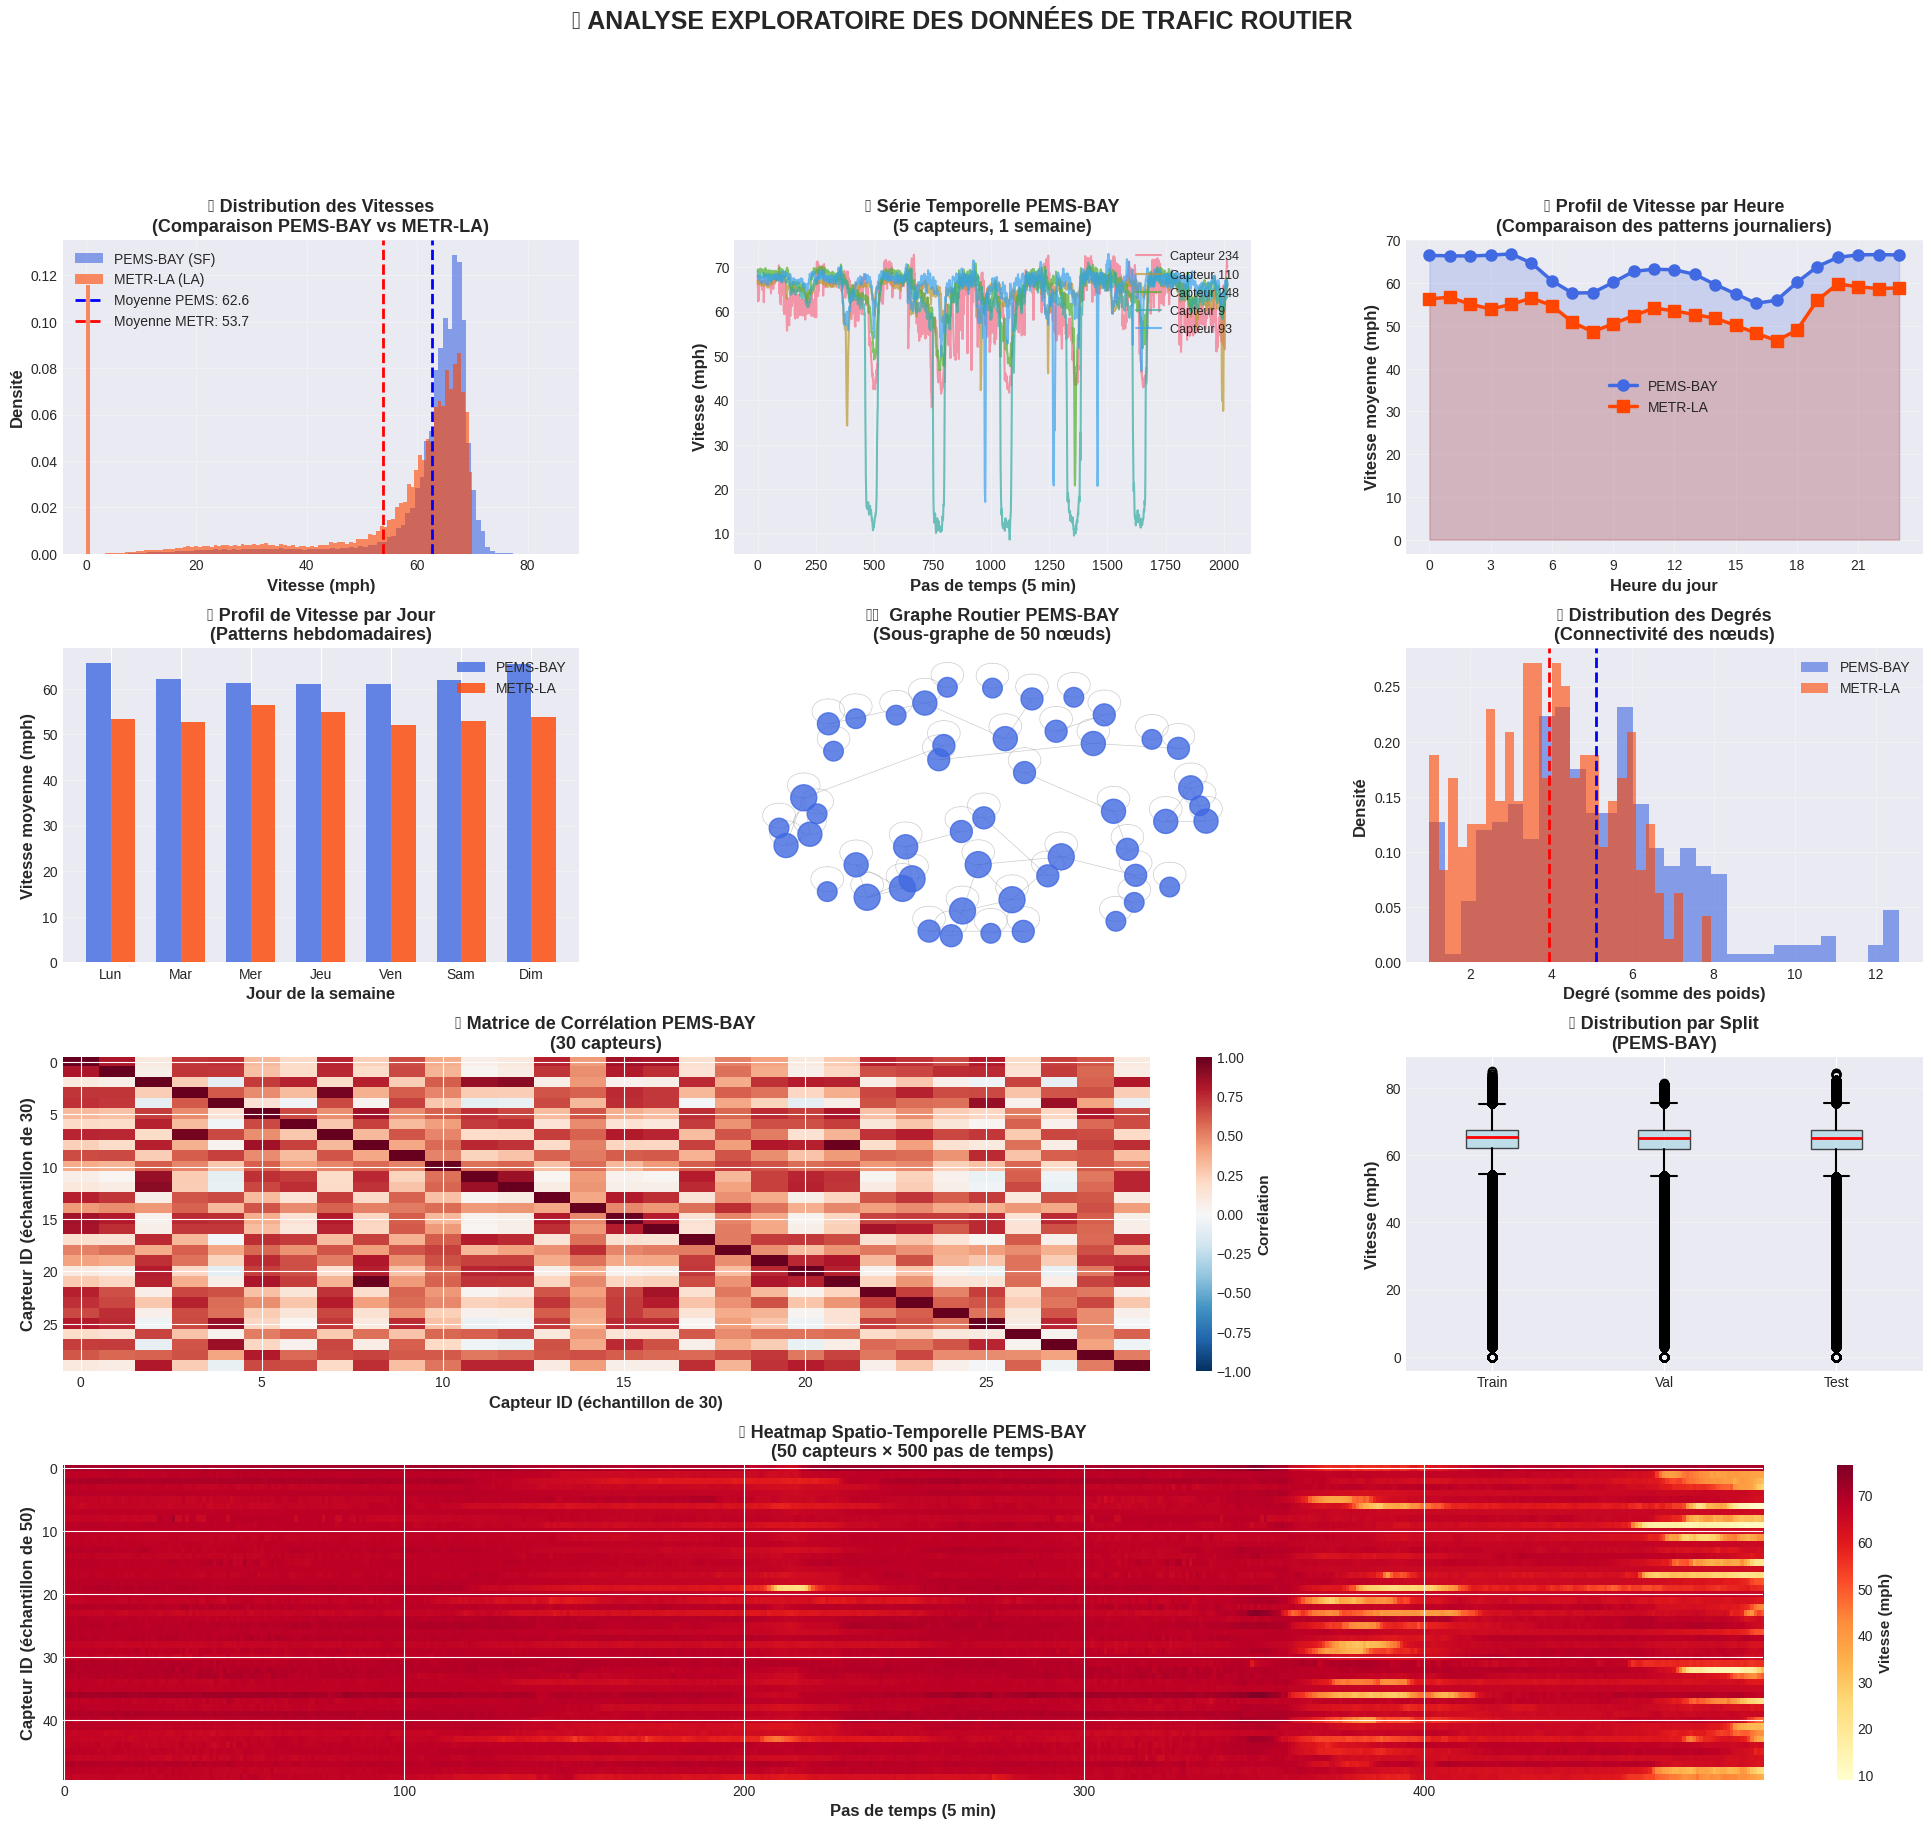


📊 INTERPRÉTATION DES VISUALISATIONS

1️⃣  DISTRIBUTION DES VITESSES :
   • Comparaison des distributions entre SF et LA
   • Permet d'identifier les différences de comportement de trafic

2️⃣  SÉRIE TEMPORELLE :
   • Visualise l'évolution temporelle sur 1 semaine
   • Montre les patterns cycliques (jour/nuit, week-end)

3️⃣  PATTERNS HORAIRES :
   • Identifie les heures de pointe (matin/soir)
   • Compare les comportements entre les deux villes

4️⃣  PATTERNS HEBDOMADAIRES :
   • Montre la différence week-end vs jours ouvrables
   • Aide à comprendre les cycles hebdomadaires

5️⃣  GRAPHE ROUTIER :
   • Visualise la topologie du réseau routier
   • Taille des nœuds = degré de connectivité

6️⃣  DISTRIBUTION DES DEGRÉS :
   • Montre comment les capteurs sont connectés
   • Compare la densité des deux réseaux

7️⃣  MATRICE DE CORRÉLATION :
   • Identifie les capteurs avec comportements similaires
   • Utile pour comprendre les dépendances spatiales

8️⃣  BOXPLOT PAR SPLIT :
   • Vérifie 

In [12]:
# =============================================================================
# SECTION 2.1: ANALYSE EXPLORATOIRE VISUELLE DES DONNÉES
# =============================================================================
print("="*80)
print("🔴 SECTION 2.5: ANALYSE EXPLORATOIRE VISUELLE DES DONNÉES")
print("="*80)
print("\n📊 Génération de 8 visualisations complètes...")
print("-" * 80)

# Création d'une figure globale
fig = plt.figure(figsize=(24, 20))
gs = GridSpec(4, 3, figure=fig, hspace=0.3, wspace=0.3)

# ============================================================================
# VIZ 1: Distribution des vitesses (PEMS-BAY vs METR-LA)
# ============================================================================
print("1️⃣  Génération : Distribution des vitesses...")
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(pems_data_raw.flatten(), bins=100, alpha=0.6, label='PEMS-BAY (SF)', color='royalblue', density=True)
ax1.hist(metr_data_raw.flatten(), bins=100, alpha=0.6, label='METR-LA (LA)', color='orangered', density=True)
ax1.axvline(pems_data_raw.mean(), color='blue', linestyle='--', linewidth=2, label=f'Moyenne PEMS: {pems_data_raw.mean():.1f}')
ax1.axvline(metr_data_raw.mean(), color='red', linestyle='--', linewidth=2, label=f'Moyenne METR: {metr_data_raw.mean():.1f}')
ax1.set_xlabel('Vitesse (mph)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Densité', fontsize=12, fontweight='bold')
ax1.set_title('📊 Distribution des Vitesses\n(Comparaison PEMS-BAY vs METR-LA)', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# ============================================================================
# VIZ 2: Série temporelle exemple (5 capteurs aléatoires, 1 semaine)
# ============================================================================
print("2️⃣  Génération : Série temporelle (échantillon 1 semaine)...")
ax2 = fig.add_subplot(gs[0, 1])
week_samples = 7 * 24 * 12  # 1 semaine à 5 min
n_sensors_to_plot = 5
random_sensors = np.random.choice(num_nodes_pems, n_sensors_to_plot, replace=False)
for i, sensor in enumerate(random_sensors):
    ax2.plot(pems_data_raw[:week_samples, sensor], alpha=0.7, linewidth=1.5, label=f'Capteur {sensor}')
ax2.set_xlabel('Pas de temps (5 min)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Vitesse (mph)', fontsize=12, fontweight='bold')
ax2.set_title(f'📈 Série Temporelle PEMS-BAY\n({n_sensors_to_plot} capteurs, 1 semaine)', fontsize=13, fontweight='bold')
ax2.legend(fontsize=9, loc='upper right')
ax2.grid(True, alpha=0.3)

# ============================================================================
# VIZ 3: Patterns horaires (moyenne par heure du jour)
# ============================================================================
print("3️⃣  Génération : Patterns horaires...")
ax3 = fig.add_subplot(gs[0, 2])
# Créer un indice temporel pour PEMS-BAY
hours_pems = np.arange(pems_data_raw.shape[0]) // 12 % 24
hourly_mean_pems = [pems_data_raw[hours_pems == h].mean() for h in range(24)]
# Créer un indice temporel pour METR-LA
hours_metr = np.arange(metr_data_raw.shape[0]) // 12 % 24
hourly_mean_metr = [metr_data_raw[hours_metr == h].mean() for h in range(24)]
ax3.plot(range(24), hourly_mean_pems, marker='o', linewidth=2.5, markersize=8, color='royalblue', label='PEMS-BAY')
ax3.plot(range(24), hourly_mean_metr, marker='s', linewidth=2.5, markersize=8, color='orangered', label='METR-LA')
ax3.fill_between(range(24), hourly_mean_pems, alpha=0.2, color='royalblue')
ax3.fill_between(range(24), hourly_mean_metr, alpha=0.2, color='orangered')
ax3.set_xlabel('Heure du jour', fontsize=12, fontweight='bold')
ax3.set_ylabel('Vitesse moyenne (mph)', fontsize=12, fontweight='bold')
ax3.set_title('🕐 Profil de Vitesse par Heure\n(Comparaison des patterns journaliers)', fontsize=13, fontweight='bold')
ax3.set_xticks(range(0, 24, 3))
ax3.legend(fontsize=10)
ax3.grid(True, alpha=0.3)

# ============================================================================
# VIZ 4: Patterns hebdomadaires (moyenne par jour de la semaine)
# ============================================================================
print("4️⃣  Génération : Patterns hebdomadaires...")
ax4 = fig.add_subplot(gs[1, 0])
days_pems = np.arange(pems_data_raw.shape[0]) // (12 * 24) % 7
daily_mean_pems = [pems_data_raw[days_pems == d].mean() for d in range(7)]
days_metr = np.arange(metr_data_raw.shape[0]) // (12 * 24) % 7
daily_mean_metr = [metr_data_raw[days_metr == d].mean() for d in range(7)]
days_labels = ['Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim']
x = np.arange(7)
width = 0.35
bars1 = ax4.bar(x - width/2, daily_mean_pems, width, label='PEMS-BAY', color='royalblue', alpha=0.8)
bars2 = ax4.bar(x + width/2, daily_mean_metr, width, label='METR-LA', color='orangered', alpha=0.8)
ax4.set_xlabel('Jour de la semaine', fontsize=12, fontweight='bold')
ax4.set_ylabel('Vitesse moyenne (mph)', fontsize=12, fontweight='bold')
ax4.set_title('📅 Profil de Vitesse par Jour\n(Patterns hebdomadaires)', fontsize=13, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels(days_labels)
ax4.legend(fontsize=10)
ax4.grid(True, alpha=0.3, axis='y')

# ============================================================================
# VIZ 5: Visualisation du graphe PEMS-BAY (sous-graphe)
# ============================================================================
print("5️⃣  Génération : Visualisation du graphe routier (PEMS-BAY)...")
ax5 = fig.add_subplot(gs[1, 1])
# Créer un sous-graphe pour la visualisation (trop de nœuds sinon)
n_nodes_viz = min(50, num_nodes_pems)
adj_sub = pems_adj[:n_nodes_viz, :n_nodes_viz]
G = nx.from_numpy_array(adj_sub)
# Retirer les arêtes faibles
edges_to_remove = [(u, v) for u, v, w in G.edges(data='weight') if w < 0.3]
G.remove_edges_from(edges_to_remove)
pos = nx.spring_layout(G, k=0.5, iterations=50, seed=config.SEED)
degrees = dict(G.degree())
node_sizes = [degrees[node] * 50 + 100 for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='royalblue', alpha=0.8, ax=ax5)
nx.draw_networkx_edges(G, pos, width=0.5, alpha=0.4, edge_color='gray', ax=ax5)
ax5.set_title(f'🗺️  Graphe Routier PEMS-BAY\n(Sous-graphe de {n_nodes_viz} nœuds)', fontsize=13, fontweight='bold')
ax5.axis('off')

# ============================================================================
# VIZ 6: Distribution des degrés du graphe
# ============================================================================
print("6️⃣  Génération : Distribution des degrés du graphe...")
ax6 = fig.add_subplot(gs[1, 2])
degrees_pems = pems_adj.sum(axis=1)
degrees_metr = metr_adj.sum(axis=1)
ax6.hist(degrees_pems, bins=30, alpha=0.6, label='PEMS-BAY', color='royalblue', density=True)
ax6.hist(degrees_metr, bins=30, alpha=0.6, label='METR-LA', color='orangered', density=True)
ax6.axvline(degrees_pems.mean(), color='blue', linestyle='--', linewidth=2)
ax6.axvline(degrees_metr.mean(), color='red', linestyle='--', linewidth=2)
ax6.set_xlabel('Degré (somme des poids)', fontsize=12, fontweight='bold')
ax6.set_ylabel('Densité', fontsize=12, fontweight='bold')
ax6.set_title('📊 Distribution des Degrés\n(Connectivité des nœuds)', fontsize=13, fontweight='bold')
ax6.legend(fontsize=10)
ax6.grid(True, alpha=0.3)

# ============================================================================
# VIZ 7: Matrice de corrélation (échantillon de capteurs)
# ============================================================================
print("7️⃣  Génération : Matrice de corrélation...")
ax7 = fig.add_subplot(gs[2, :2])
n_sensors_corr = min(30, num_nodes_pems)
sample_sensors = np.random.choice(num_nodes_pems, n_sensors_corr, replace=False)
sample_data = pems_data_raw[:5000, sample_sensors]  # 5000 premiers pas
corr_matrix = np.corrcoef(sample_data.T)
im = ax7.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax7.set_xlabel(f'Capteur ID (échantillon de {n_sensors_corr})', fontsize=12, fontweight='bold')
ax7.set_ylabel(f'Capteur ID (échantillon de {n_sensors_corr})', fontsize=12, fontweight='bold')
ax7.set_title(f'🔗 Matrice de Corrélation PEMS-BAY\n({n_sensors_corr} capteurs)', fontsize=13, fontweight='bold')
cbar = plt.colorbar(im, ax=ax7, fraction=0.046, pad=0.04)
cbar.set_label('Corrélation', fontsize=11, fontweight='bold')

# ============================================================================
# VIZ 8: Boxplot des vitesses par split (train/val/test)
# ============================================================================
print("8️⃣  Génération : Boxplot des distributions par split...")
ax8 = fig.add_subplot(gs[2, 2])
data_splits = [
    pems_train_raw.flatten(),
    pems_val_raw.flatten(),
    pems_test_raw.flatten()
]
bp = ax8.boxplot(data_splits, labels=['Train', 'Val', 'Test'], patch_artist=True,
                  medianprops=dict(color='red', linewidth=2),
                  boxprops=dict(facecolor='lightblue', alpha=0.7),
                  whiskerprops=dict(linewidth=1.5),
                  capprops=dict(linewidth=1.5))
ax8.set_ylabel('Vitesse (mph)', fontsize=12, fontweight='bold')
ax8.set_title('📦 Distribution par Split\n(PEMS-BAY)', fontsize=13, fontweight='bold')
ax8.grid(True, alpha=0.3, axis='y')

# ============================================================================
# VIZ 9: Heatmap temporelle (capteurs × temps)
# ============================================================================
print("9️⃣  Génération : Heatmap spatio-temporelle...")
ax9 = fig.add_subplot(gs[3, :])
n_sensors_heatmap = min(50, num_nodes_pems)
n_time_heatmap = min(500, pems_data_raw.shape[0])
heatmap_data = pems_data_raw[:n_time_heatmap, :n_sensors_heatmap].T
im2 = ax9.imshow(heatmap_data, cmap='YlOrRd', aspect='auto', interpolation='nearest')
ax9.set_xlabel('Pas de temps (5 min)', fontsize=12, fontweight='bold')
ax9.set_ylabel(f'Capteur ID (échantillon de {n_sensors_heatmap})', fontsize=12, fontweight='bold')
ax9.set_title(f'🔥 Heatmap Spatio-Temporelle PEMS-BAY\n({n_sensors_heatmap} capteurs × {n_time_heatmap} pas de temps)',
              fontsize=13, fontweight='bold')
cbar2 = plt.colorbar(im2, ax=ax9, fraction=0.046, pad=0.04)
cbar2.set_label('Vitesse (mph)', fontsize=11, fontweight='bold')

plt.suptitle('🚦 ANALYSE EXPLORATOIRE DES DONNÉES DE TRAFIC ROUTIER',
             fontsize=18, fontweight='bold', y=0.995)

# Sauvegarde
viz_path = os.path.join(config.RESULTS_SAVE_PATH, 'data_exploration.png')
plt.savefig(viz_path, dpi=150, bbox_inches='tight', facecolor='white')
print(f"\n💾 Visualisations sauvegardées : {viz_path}")

plt.show()

print("\n" + "="*80)
print("📊 INTERPRÉTATION DES VISUALISATIONS")
print("="*80)
print("""
1️⃣  DISTRIBUTION DES VITESSES :
   • Comparaison des distributions entre SF et LA
   • Permet d'identifier les différences de comportement de trafic

2️⃣  SÉRIE TEMPORELLE :
   • Visualise l'évolution temporelle sur 1 semaine
   • Montre les patterns cycliques (jour/nuit, week-end)

3️⃣  PATTERNS HORAIRES :
   • Identifie les heures de pointe (matin/soir)
   • Compare les comportements entre les deux villes

4️⃣  PATTERNS HEBDOMADAIRES :
   • Montre la différence week-end vs jours ouvrables
   • Aide à comprendre les cycles hebdomadaires

5️⃣  GRAPHE ROUTIER :
   • Visualise la topologie du réseau routier
   • Taille des nœuds = degré de connectivité

6️⃣  DISTRIBUTION DES DEGRÉS :
   • Montre comment les capteurs sont connectés
   • Compare la densité des deux réseaux

7️⃣  MATRICE DE CORRÉLATION :
   • Identifie les capteurs avec comportements similaires
   • Utile pour comprendre les dépendances spatiales

8️⃣  BOXPLOT PAR SPLIT :
   • Vérifie que train/val/test ont des distributions similaires
   • Détecte d'éventuels biais dans le découpage

9️⃣  HEATMAP SPATIO-TEMPORELLE :
   • Vue d'ensemble des patterns spatio-temporels
   • Les zones rouges indiquent les zones/moments de trafic dense
""")

print("="*80)
print("✅ SECTION 2.5 TERMINÉE : Analyse visuelle complète")
print("="*80 + "\n")



## 🧠 Section 3 — Définition du modèle hybride GNN-Transformer

Architecture complète :
- `SpatialGNN` : couches GCN ou GAT pour les dépendances spatiales
- `AdaptiveTransformer` : Transformer temporel avec attention adaptative
- `HybridTrafficModel` : combinaison des deux blocs + tête de prédiction

In [13]:
# =============================================================================
# SECTION 3: DÉFINITION DU MODÈLE HYBRIDE
# =============================================================================
print("="*80)
print("🔴 SECTION 3: DÉFINITION DU MODÈLE HYBRIDE GNN-TRANSFORMER")
print("="*80)

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class DynamicAdaptiveAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.1):
        super().__init__()
        self.num_heads = num_heads
        self.embed_dim = embed_dim
        self.head_dim  = embed_dim // num_heads
        assert self.head_dim * num_heads == embed_dim, "embed_dim doit être divisible par num_heads"
        self.attention = nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout, batch_first=True)
        self.context_gate = nn.Sequential(nn.Linear(embed_dim, num_heads), nn.Sigmoid())
        self.adaptive_scale = nn.Parameter(torch.ones(num_heads))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        context = x.mean(dim=1)
        gate_weights = self.context_gate(context)
        head_gain = gate_weights * self.adaptive_scale
        head_gain_expanded = head_gain.repeat_interleave(self.head_dim, dim=1)
        attn_output, attn_weights = self.attention(x, x, x, key_padding_mask=mask)
        attn_output = attn_output * head_gain_expanded.unsqueeze(1)
        attn_output = self.dropout(attn_output)
        return attn_output, attn_weights

class SpatialGNNLayer(nn.Module):
    def __init__(self, in_features, out_features, dropout=0.1, use_gat=False):
        super().__init__()
        self.use_gat = use_gat
        if use_gat:
            self.conv = GATConv(in_features, out_features, heads=4, concat=False, dropout=dropout)
        else:
            self.conv = GCNConv(in_features, out_features)
        self.bn = nn.BatchNorm1d(out_features)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index, edge_weight=None):
        if self.use_gat:
            x = self.conv(x, edge_index)
        else:
            x = self.conv(x, edge_index, edge_weight=edge_weight)
        x = self.bn(x)
        x = F.relu(x)
        x = self.dropout(x)
        return x

class TemporalTransformerLayer(nn.Module):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1):
        super().__init__()
        self.attention = DynamicAdaptiveAttention(embed_dim, num_heads, dropout)
        self.feed_forward = nn.Sequential(
            nn.Linear(embed_dim, ff_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, embed_dim),
            nn.Dropout(dropout)
        )
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        attn_out, _ = self.attention(self.norm1(x), mask)
        x = x + self.dropout(attn_out)
        ff_out = self.feed_forward(self.norm2(x))
        x = x + ff_out
        return x

class SpatioTemporalGNNTransformer(nn.Module):
    def __init__(self,
                 num_nodes,
                 node_features,
                 seq_len,
                 pred_len=12,
                 embed_dim=64,
                 gnn_hidden=64,
                 gnn_layers=3,
                 transformer_layers=3,
                 num_heads=8,
                 ff_dim=256,
                 dropout=0.1,
                 use_gat=False):
        super().__init__()
        self.num_nodes = num_nodes
        self.seq_len   = seq_len
        self.pred_len  = pred_len
        self.embed_dim = embed_dim

        self.input_embedding = nn.Linear(node_features, gnn_hidden)
        self.gnn_layers = nn.ModuleList([
            SpatialGNNLayer(gnn_hidden, gnn_hidden, dropout=dropout, use_gat=use_gat)
            for _ in range(gnn_layers)
        ])
        self.spatial_to_temporal = nn.Linear(gnn_hidden, embed_dim)
        self.pos_encoding = PositionalEncoding(embed_dim, max_len=seq_len)
        self.temporal_layers = nn.ModuleList([
            TemporalTransformerLayer(embed_dim, num_heads, ff_dim, dropout)
            for _ in range(transformer_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.decoder = nn.Sequential(
            nn.Linear(embed_dim, ff_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, pred_len)
        )
        self.dropout = nn.Dropout(dropout)
        self._graph_cache = {}

    def _batch_graph(self, edge_index, edge_weight, num_graphs, device):
        E = edge_index.size(1)
        dev_key = str(device)
        use_w = 1 if edge_weight is not None else 0
        key = (num_graphs, dev_key, self.num_nodes, E, use_w)
        if key in self._graph_cache:
            return self._graph_cache[key]
        ei = edge_index.to(device).repeat(1, num_graphs)
        offsets = (torch.arange(num_graphs, device=device).repeat_interleave(E) * self.num_nodes)
        ei = ei + offsets.unsqueeze(0)
        ew = None if edge_weight is None else edge_weight.to(device).repeat(num_graphs)
        assert ei.max().item() < num_graphs * self.num_nodes
        self._graph_cache[key] = (ei, ew)
        return ei, ew

    def forward(self, x, edge_index, edge_weight=None, batch_idx=None):
        batch_size = x.size(0) // (self.num_nodes * self.seq_len)
        device = x.device
        x = self.input_embedding(x)
        H = x.size(-1)
        x = x.view(batch_size, self.seq_len, self.num_nodes, H)
        x = x.permute(0, 1, 2, 3).contiguous().view(batch_size*self.seq_len*self.num_nodes, H)
        ei_bl, ew_bl = self._batch_graph(edge_index, edge_weight, batch_size * self.seq_len, device)
        for gnn_layer in self.gnn_layers:
            x = gnn_layer(x, ei_bl, ew_bl)
        x = x.view(batch_size, self.seq_len, self.num_nodes, H)
        x = x.permute(0, 2, 1, 3).contiguous()
        x = self.spatial_to_temporal(x)
        x = x.view(batch_size * self.num_nodes, self.seq_len, self.embed_dim)
        x = self.pos_encoding(x)
        x = self.dropout(x)
        for temporal_layer in self.temporal_layers:
            x = temporal_layer(x)
        x = x.view(batch_size, self.num_nodes, self.seq_len, self.embed_dim)
        x = self.final_norm(x)
        x = x[:, :, -1, :]
        preds = self.decoder(x)
        return preds

print("\n🏗️  ARCHITECTURE DU MODÈLE")
print("-" * 80)
print("""
Le modèle hybride combine :

1️⃣  GNN SPATIAL (Graph Neural Network)
   ├─ Couches : GCNConv ou GATConv
   ├─ Rôle : Apprendre les dépendances spatiales entre capteurs
   └─ BatchNorm + ReLU + Dropout pour la régularisation

2️⃣  TRANSFORMER TEMPOREL
   ├─ Encodage positionnel sinusoïdal
   ├─ Attention multi-têtes avec pondération adaptative
   ├─ Feed-forward avec GELU activation
   └─ Layer Normalization

3️⃣  ATTENTION ADAPTATIVE DYNAMIQUE
   ├─ Context gate : ajuste les poids d'attention selon le contexte
   ├─ Adaptive scale : paramètres apprenables par tête
   └─ Permet au modèle de s'adapter aux différents patterns

4️⃣  DÉCODEUR
   ├─ MLP avec GELU
   └─ Projection vers l'horizon de prédiction
""")

# Créer une instance de test
test_model = SpatioTemporalGNNTransformer(
    num_nodes=num_nodes_pems,
    node_features=num_features,
    seq_len=config.SEQ_LEN,
    pred_len=config.PRED_LEN,
    embed_dim=config.DEFAULT_EMBED_DIM,
    gnn_hidden=config.DEFAULT_GNN_HIDDEN,
    gnn_layers=config.DEFAULT_GNN_LAYERS,
    transformer_layers=config.DEFAULT_TRANSFORMER_LAYERS,
    num_heads=config.DEFAULT_NUM_HEADS,
    ff_dim=config.DEFAULT_FF_DIM,
    dropout=config.DEFAULT_DROPOUT,
    use_gat=config.DEFAULT_USE_GAT
)

total_params = sum(p.numel() for p in test_model.parameters())
trainable_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)

print("\n📊 STATISTIQUES DU MODÈLE (configuration par défaut)")
print("-" * 80)
print(f"├─ Nombre total de paramètres : {total_params:,}")
print(f"├─ Paramètres entraînables : {trainable_params:,}")
print(f"├─ Mémoire approximative : {total_params * 4 / 1024 / 1024:.2f} MB (float32)")
print(f"└─ Architecture : {config.DEFAULT_GNN_LAYERS} GNN + {config.DEFAULT_TRANSFORMER_LAYERS} Transformer")

del test_model  # Libérer la mémoire

print("\n✅ SECTION 3 TERMINÉE : Architecture définie")
print("="*80 + "\n")




🔴 SECTION 3: DÉFINITION DU MODÈLE HYBRIDE GNN-TRANSFORMER

🏗️  ARCHITECTURE DU MODÈLE
--------------------------------------------------------------------------------

Le modèle hybride combine :

1️⃣  GNN SPATIAL (Graph Neural Network)
   ├─ Couches : GCNConv ou GATConv
   ├─ Rôle : Apprendre les dépendances spatiales entre capteurs
   └─ BatchNorm + ReLU + Dropout pour la régularisation

2️⃣  TRANSFORMER TEMPOREL
   ├─ Encodage positionnel sinusoïdal
   ├─ Attention multi-têtes avec pondération adaptative
   ├─ Feed-forward avec GELU activation
   └─ Layer Normalization

3️⃣  ATTENTION ADAPTATIVE DYNAMIQUE
   ├─ Context gate : ajuste les poids d'attention selon le contexte
   ├─ Adaptive scale : paramètres apprenables par tête
   └─ Permet au modèle de s'adapter aux différents patterns

4️⃣  DÉCODEUR
   ├─ MLP avec GELU
   └─ Projection vers l'horizon de prédiction


📊 STATISTIQUES DU MODÈLE (configuration par défaut)
------------------------------------------------------------------

## ⚙️ Section 4 — Datasets & DataLoaders

Création des `Dataset` PyTorch avec fenêtrage glissant (L=12 entrée, P=12 sortie) et des `DataLoader` pour train / val / test.

Le dataset est construit par une fenêtre glissante qui transforme la série temporelle brute en exemples d’apprentissage, où les séquences passées servent à prédire les séquences futures.

Dataset

chaque exemple :

INPUT  = passé du trafic

OUTPUT = futur du trafic

In [14]:
# =============================================================================
# SECTION 4: DATASETS & DATALOADERS
# =============================================================================
print("="*80)
print("🔴 SECTION 4: DATASETS & DATALOADERS")
print("="*80)

class SpatioTemporalDataset(torch.utils.data.Dataset):
    def __init__(self, data, seq_len, pred_len):
        self.data = torch.FloatTensor(data)  # [T, N, 1]
        self.seq_len = seq_len
        self.pred_len = pred_len
        self.num_samples = len(data) - seq_len - pred_len + 1

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        x = self.data[idx:idx+self.seq_len]                            # [L,N,1]
        y = self.data[idx+self.seq_len:idx+self.seq_len+self.pred_len] # [P,N,1]
        return x, y

train_dataset = SpatioTemporalDataset(pems_train, config.SEQ_LEN, config.PRED_LEN)
val_dataset   = SpatioTemporalDataset(pems_val,   config.SEQ_LEN, config.PRED_LEN)
test_dataset  = SpatioTemporalDataset(pems_test,  config.SEQ_LEN, config.PRED_LEN)

pin = (config.DEVICE == 'cuda')
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=config.BATCH_SIZE, shuffle=True,
    num_workers=config.NUM_WORKERS, drop_last=True, pin_memory=pin
)
val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=config.BATCH_SIZE, shuffle=False,
    num_workers=config.NUM_WORKERS, drop_last=False, pin_memory=pin
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=config.BATCH_SIZE, shuffle=False,
    num_workers=config.NUM_WORKERS, drop_last=False, pin_memory=pin
)



🔴 SECTION 4: DATASETS & DATALOADERS


## ⚙️ Section 5 — Métriques d'évaluation

Fonctions de calcul : MSE, RMSE, MAE, MAPE (robuste, mode masqué), R².

In [15]:
# =============================================================================
# SECTION 5: MÉTRIQUES
# =============================================================================
print("="*80)
print("🔴 SECTION 5: MÉTRIQUES")
print("="*80)

def calculate_metrics(predictions, targets, denormalize=False, mean=0.0, std=1.0):
    if targets.dim() == 4:
        targets = targets[:, :, :, 0]
        targets = targets.permute(0, 2, 1)
    if predictions.shape != targets.shape:
        min_nodes = min(predictions.shape[1], targets.shape[1])
        predictions = predictions[:, :min_nodes, :]
        targets     = targets[:, :min_nodes, :]
    if denormalize:
        predictions = predictions * std + mean
        targets     = targets * std + mean
    mse  = F.mse_loss(predictions, targets).item()
    rmse = torch.sqrt(F.mse_loss(predictions, targets)).item()
    mae  = F.l1_loss(predictions, targets).item()
    eps  = 1e-8
    if config.MAPE_MODE.lower() == 'smape':
        mape_tensor = 200.0 * torch.abs(predictions - targets) / (torch.abs(predictions) + torch.abs(targets) + eps)
        mape = mape_tensor.mean().item()
    elif config.MAPE_MODE.lower() == 'masked':
        mask = torch.abs(targets) >= config.MAPE_THRESHOLD
        if mask.any():
            mape_tensor = torch.abs((targets - predictions) / (torch.abs(targets) + eps))
            mape = mape_tensor[mask].mean().item() * 100.0
        else:
            mape = 0.0
    else:
        mape = (torch.abs((targets - predictions) / (torch.abs(targets) + eps)).mean() * 100.0).item()
    ss_res = torch.sum((targets - predictions) ** 2)
    ss_tot = torch.sum((targets - torch.mean(targets)) ** 2) + 1e-8
    r2 = 1 - (ss_res / ss_tot)
    r2 = r2.item()
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'R2': r2}

def compute_aggregate_metrics(preds_list, tgts_list, denormalize=False, mean=0.0, std=1.0):
    P = torch.cat(preds_list, 0)
    T = torch.cat(tgts_list, 0)
    return calculate_metrics(P, T, denormalize=denormalize, mean=mean, std=std)



🔴 SECTION 5: MÉTRIQUES


## ⚙️ Section 6 — Fonctions d'entraînement et d'évaluation

Boucles d'entraînement avec AMP (précision mixte), early stopping, et évaluation agrégée sur l'ensemble de test.

In [16]:
# =============================================================================
# SECTION 6: ENTRAÎNEMENT / ÉVALUATION (AMP + AGGRÉGÉ)
# =============================================================================
print("="*80)
print("🔴 SECTION 6: ENTRAÎNEMENT & ÉVALUATION")
print("="*80)

def train_epoch(model, train_loader, edge_index, edge_weight,
                optimizer, criterion, device, epoch, total_epochs,
                norm_stats=None, denorm_metrics=True, max_batches=None):
    model.train()
    total_metrics = {'MSE': 0, 'RMSE': 0, 'MAE': 0, 'MAPE': 0, 'R2': 0}
    total_loss = 0.0
    processed = 0
    num_batches = len(train_loader)
    limit = min(num_batches, max_batches) if max_batches is not None else num_batches
    iterator = train_loader if max_batches is None else itertools.islice(train_loader, limit)
    mode = "FAST" if max_batches is not None else "FULL"
    use_amp = config.USE_AMP and (device == 'cuda')
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    for batch_idx, (batch_x, batch_y) in enumerate(iterator):
        batch_x = batch_x.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)
        B, L, N, F_in = batch_x.shape
        x = batch_x.permute(0, 2, 1, 3).contiguous().reshape(-1, F_in)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            predictions = model(x, edge_index, edge_weight)
            targets     = batch_y[:, :, :, 0].permute(0, 2, 1)
            if predictions.shape[1] != targets.shape[1]:
                min_nodes = min(predictions.shape[1], targets.shape[1])
                predictions = predictions[:, :min_nodes, :]
                targets     = targets[:, :min_nodes, :]
            loss = criterion(predictions, targets)
        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.GRADIENT_CLIP_VALUE)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.GRADIENT_CLIP_VALUE)
            optimizer.step()

        with torch.no_grad():
            use_denorm = denorm_metrics and (norm_stats is not None)
            mean, std = (norm_stats if use_denorm else (0.0, 1.0))
            metrics = calculate_metrics(predictions, targets, denormalize=use_denorm, mean=mean, std=std)
            for k in total_metrics:
                total_metrics[k] += metrics[k]
        total_loss += loss.item()
        processed += 1

    processed = max(1, processed)
    for k in total_metrics:
        total_metrics[k] /= processed
    avg_loss = total_loss / processed

    print(f"[Train {mode}] Epoch {epoch}/{total_epochs} - Loss: {avg_loss:.6f} | "
          f"MAE: {total_metrics['MAE']:.6f} | MAPE: {total_metrics['MAPE']:.2f}% | R²: {total_metrics['R2']:.4f}")
    return total_metrics

def evaluate(model, val_loader, edge_index, edge_weight,
             criterion, device, phase="Validation",
             norm_stats=None, denorm_metrics=True, max_batches=None):
    """
    Évaluation agrégée: concatène toutes les prédictions et cibles traitées (max_batches appliqué si fourni),
    puis calcule les métriques une fois (R² stable).
    """
    model.eval()
    num_batches = len(val_loader)
    limit = min(num_batches, max_batches) if max_batches is not None else num_batches
    iterator = val_loader if max_batches is None else itertools.islice(val_loader, limit)
    mode = "FAST" if max_batches is not None else "FULL"
    use_amp = config.USE_AMP and (device == 'cuda')

    preds_all, tgts_all = [], []
    with torch.no_grad():
        for batch_idx, (batch_x, batch_y) in enumerate(iterator):
            batch_x = batch_x.to(device, non_blocking=True)
            batch_y = batch_y.to(device, non_blocking=True)
            B, L, N, F_in = batch_x.shape
            x = batch_x.permute(0, 2, 1, 3).contiguous().reshape(-1, F_in)
            with torch.cuda.amp.autocast(enabled=use_amp):
                predictions = model(x, edge_index, edge_weight)          # [B,N,P]
                targets     = batch_y[:, :, :, 0].permute(0, 2, 1)       # [B,N,P]
            preds_all.append(predictions.detach().cpu())
            tgts_all.append(targets.detach().cpu())

    use_denorm = denorm_metrics and (norm_stats is not None)
    mean, std = (norm_stats if use_denorm else (0.0, 1.0))
    metrics = compute_aggregate_metrics(preds_all, tgts_all, denormalize=use_denorm, mean=mean, std=std)
    print(f"[{phase} {mode}] - MSE: {metrics['MSE']:.6f} | RMSE: {metrics['RMSE']:.6f} | "
          f"MAE: {metrics['MAE']:.6f} | MAPE: {metrics['MAPE']:.2f}% | R²: {metrics['R2']:.4f}")
    return metrics

print("Boucles prêtes (AMP + AGGREGATION pour l'éval)")



🔴 SECTION 6: ENTRAÎNEMENT & ÉVALUATION
Boucles prêtes (AMP + AGGREGATION pour l'éval)


## ⚙️ Section 7 — Optimisation des hyperparamètres (Optuna)

Recherche automatique des meilleurs hyperparamètres via Optuna (`N_TRIALS = 2` en mode rapide).  
Résultat sauvegardé dans `best_hyperparameters.json`.

In [17]:
# =============================================================================
# SECTION 7: OPTIMISATION DES HYPERPARAMÈTRES (OPTUNA)
# =============================================================================
print("="*80)
print("🔴 SECTION 7: OPTIMISATION HP (Optuna)")
print("="*80)

def objective(trial):
    embed_dim = trial.suggest_categorical('embed_dim', [32, 64, 128])
    gnn_hidden = trial.suggest_categorical('gnn_hidden', [32, 64, 128])
    gnn_layers = trial.suggest_int('gnn_layers', 2, 4)
    transformer_layers = trial.suggest_int('transformer_layers', 2, 4)
    possible_heads = [h for h in [2, 4, 8] if embed_dim % h == 0]
    num_heads = trial.suggest_categorical('num_heads', possible_heads)
    ff_dim = trial.suggest_categorical('ff_dim', [128, 256, 512])
    dropout = trial.suggest_float('dropout', 0.0, 0.3, step=0.1)
    use_gat = trial.suggest_categorical('use_gat', [True, False])
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [16, 32])

    model = SpatioTemporalGNNTransformer(
        num_nodes=num_nodes_pems,
        node_features=1,
        seq_len=config.SEQ_LEN,
        pred_len=config.PRED_LEN,
        embed_dim=embed_dim,
        gnn_hidden=gnn_hidden,
        gnn_layers=gnn_layers,
        transformer_layers=transformer_layers,
        num_heads=num_heads,
        ff_dim=ff_dim,
        dropout=dropout,
        use_gat=use_gat
    ).to(config.DEVICE)

    pin_local = (config.DEVICE == 'cuda')
    train_loader_trial = torch.utils.data.DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, num_workers=0,
        pin_memory=pin_local
    )
    val_loader_trial = torch.utils.data.DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False, num_workers=0,
        pin_memory=pin_local
    )

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=config.WEIGHT_DECAY)
    criterion = nn.MSELoss()

    edge_index  = pems_edge_index_gat if use_gat else pems_edge_index_gcn
    edge_weight = pems_edge_weight_gat if use_gat else pems_edge_weight_gcn

    if config.OPTUNA_FAST:
        num_epochs_optuna  = config.OPTUNA_FAST_EPOCHS
        max_train_batches  = config.OPTUNA_FAST_MAX_TRAIN_B
        max_val_batches    = config.OPTUNA_FAST_MAX_VAL_B
    else:
        num_epochs_optuna  = 10
        max_train_batches  = None
        max_val_batches    = None

    best_val_mae = float('inf')
    for epoch in range(1, num_epochs_optuna + 1):
        _ = train_epoch(
            model, train_loader_trial, edge_index, edge_weight,
            optimizer, criterion, config.DEVICE, epoch, num_epochs_optuna,
            norm_stats=(pems_mean_train, pems_std_train), denorm_metrics=True,
            max_batches=max_train_batches
        )
        val_metrics = evaluate(
            model, val_loader_trial, edge_index, edge_weight,
            criterion, config.DEVICE, "Validation",
            norm_stats=(pems_mean_train, pems_std_train), denorm_metrics=True,
            max_batches=max_val_batches
        )
        best_val_mae = min(best_val_mae, val_metrics['MAE'])
        trial.report(val_metrics['MAE'], epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    del model
    if config.DEVICE == 'cuda':
        torch.cuda.empty_cache()
    return best_val_mae

study = optuna.create_study(
    direction='minimize',
    study_name=config.OPTUNA_STUDY_NAME,
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=3,
        n_warmup_steps=config.OPTUNA_PRUNING_WARMUP
    )
)
study.optimize(objective, n_trials=config.OPTUNA_N_TRIALS)

best_params = study.best_params
with open('best_hyperparameters.json', 'w') as f:
    json.dump(best_params, f, indent=4)
print("Meilleurs hyperparamètres:", best_params)



[I 2026-04-10 15:01:04,352] A new study created in memory with name: gnn_transformer_optimization


🔴 SECTION 7: OPTIMISATION HP (Optuna)
[Train FAST] Epoch 1/5 - Loss: 0.897054 | MAE: 5.367392 | MAPE: 13.33% | R²: 0.1327
[Validation FAST] - MSE: 107.192116 | RMSE: 10.353362 | MAE: 7.156490 | MAPE: 16.64% | R²: 0.1009
[Train FAST] Epoch 2/5 - Loss: 0.859736 | MAE: 5.209085 | MAPE: 12.84% | R²: 0.1391
[Validation FAST] - MSE: 96.945969 | RMSE: 9.846114 | MAE: 5.720747 | MAPE: 15.61% | R²: 0.1868
[Train FAST] Epoch 3/5 - Loss: 0.816026 | MAE: 5.068588 | MAPE: 12.40% | R²: 0.1599
[Validation FAST] - MSE: 123.300674 | RMSE: 11.104084 | MAE: 9.047259 | MAPE: 19.46% | R²: -0.0342
[Train FAST] Epoch 4/5 - Loss: 0.759528 | MAE: 4.846692 | MAPE: 11.61% | R²: 0.1585
[Validation FAST] - MSE: 101.855148 | RMSE: 10.092331 | MAE: 6.821622 | MAPE: 16.30% | R²: 0.1457
[Train FAST] Epoch 5/5 - Loss: 0.837295 | MAE: 5.155448 | MAPE: 12.68% | R²: 0.1483


[I 2026-04-10 15:02:01,713] Trial 0 finished with value: 5.720747470855713 and parameters: {'embed_dim': 32, 'gnn_hidden': 32, 'gnn_layers': 4, 'transformer_layers': 4, 'num_heads': 8, 'ff_dim': 128, 'dropout': 0.2, 'use_gat': False, 'lr': 0.008877120152936865, 'batch_size': 16}. Best is trial 0 with value: 5.720747470855713.


[Validation FAST] - MSE: 95.838341 | RMSE: 9.789706 | MAE: 5.924577 | MAPE: 15.79% | R²: 0.1961
[Train FAST] Epoch 1/5 - Loss: 0.978405 | MAE: 5.557941 | MAPE: 13.81% | R²: 0.0298
[Validation FAST] - MSE: 101.148735 | RMSE: 10.057273 | MAE: 5.973750 | MAPE: 15.99% | R²: 0.1516
[Train FAST] Epoch 2/5 - Loss: 0.889680 | MAE: 5.342134 | MAPE: 13.13% | R²: 0.0947
[Validation FAST] - MSE: 101.164062 | RMSE: 10.058035 | MAE: 5.960348 | MAPE: 15.91% | R²: 0.1515
[Train FAST] Epoch 3/5 - Loss: 0.879774 | MAE: 5.296998 | MAPE: 13.09% | R²: 0.1047
[Validation FAST] - MSE: 100.498215 | RMSE: 10.024879 | MAE: 5.949018 | MAPE: 15.84% | R²: 0.1570
[Train FAST] Epoch 4/5 - Loss: 0.827419 | MAE: 5.126069 | MAPE: 12.48% | R²: 0.1182
[Validation FAST] - MSE: 100.273956 | RMSE: 10.013688 | MAE: 5.998676 | MAPE: 15.85% | R²: 0.1589
[Train FAST] Epoch 5/5 - Loss: 0.857752 | MAE: 5.232731 | MAPE: 12.80% | R²: 0.1184


[I 2026-04-10 15:02:36,775] Trial 1 finished with value: 5.9047017097473145 and parameters: {'embed_dim': 32, 'gnn_hidden': 32, 'gnn_layers': 2, 'transformer_layers': 2, 'num_heads': 8, 'ff_dim': 512, 'dropout': 0.3, 'use_gat': False, 'lr': 0.00011265404521151786, 'batch_size': 16}. Best is trial 0 with value: 5.720747470855713.


[Validation FAST] - MSE: 99.038643 | RMSE: 9.951816 | MAE: 5.904702 | MAPE: 15.76% | R²: 0.1693
Meilleurs hyperparamètres: {'embed_dim': 32, 'gnn_hidden': 32, 'gnn_layers': 4, 'transformer_layers': 4, 'num_heads': 8, 'ff_dim': 128, 'dropout': 0.2, 'use_gat': False, 'lr': 0.008877120152936865, 'batch_size': 16}


## ⚙️ Section 8 — Entraînement final

Entraînement complet sur PEMS-BAY avec les meilleurs hyperparamètres trouvés.  
Checkpoint sauvegardé dans `best_model.pth`.

In [18]:
# =============================================================================
# SECTION 8: ENTRAÎNEMENT FINAL
# =============================================================================
print("="*80)
print("🔴 SECTION 8: ENTRAÎNEMENT FINAL")
print("="*80)

final_model = SpatioTemporalGNNTransformer(
    num_nodes=num_nodes_pems,
    node_features=1,
    seq_len=config.SEQ_LEN,
    pred_len=config.PRED_LEN,
    embed_dim=best_params['embed_dim'],
    gnn_hidden=best_params['gnn_hidden'],
    gnn_layers=best_params['gnn_layers'],
    transformer_layers=best_params['transformer_layers'],
    num_heads=best_params['num_heads'],
    ff_dim=best_params['ff_dim'],
    dropout=best_params['dropout'],
    use_gat=best_params['use_gat']
).to(config.DEVICE)

final_train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=best_params['batch_size'], shuffle=True,
    num_workers=config.NUM_WORKERS, pin_memory=pin
)
final_val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=best_params['batch_size'], shuffle=False,
    num_workers=config.NUM_WORKERS, pin_memory=pin
)

optimizer = torch.optim.AdamW(final_model.parameters(), lr=best_params['lr'], weight_decay=config.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config.MAX_EPOCHS)
criterion = nn.MSELoss()

edge_index  = pems_edge_index_gat if best_params['use_gat'] else pems_edge_index_gcn
edge_weight = pems_edge_weight_gat if best_params['use_gat'] else pems_edge_weight_gcn

history = {'train_metrics': [], 'val_metrics': [], 'epochs': []}
best_val_mae = float('inf')
patience_counter = 0

for epoch in range(1, config.MAX_EPOCHS + 1):
    train_metrics = train_epoch(
        final_model, final_train_loader, edge_index, edge_weight,
        optimizer, criterion, config.DEVICE, epoch, config.MAX_EPOCHS,
        norm_stats=(pems_mean_train, pems_std_train), denorm_metrics=True
    )
    val_metrics = evaluate(
        final_model, final_val_loader, edge_index, edge_weight,
        criterion, config.DEVICE, "Validation",
        norm_stats=(pems_mean_train, pems_std_train), denorm_metrics=True
    )
    scheduler.step()
    history['train_metrics'].append(train_metrics)
    history['val_metrics'].append(val_metrics)
    history['epochs'].append(epoch)

    if val_metrics['MAE'] < best_val_mae:
        best_val_mae = val_metrics['MAE']
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': final_model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_mae': best_val_mae,
            'hyperparameters': best_params,
            'history': history,
            'pems_mean_train': pems_mean_train,
            'pems_std_train': pems_std_train
        }, config.MODEL_SAVE_PATH)
        print(f"✓ Nouveau meilleur modèle sauvegardé! MAE: {best_val_mae:.6f}")
    else:
        patience_counter += 1
        print(f"Pas d'amélioration. Patience: {patience_counter}/{config.EARLY_STOPPING_PATIENCE}")
        if patience_counter >= config.EARLY_STOPPING_PATIENCE:
            print(f"Early stopping à l'époque {epoch}")
            break
#Rechargement du meilleur modèle
checkpoint = torch.load(config.MODEL_SAVE_PATH, map_location=config.DEVICE)
final_model.load_state_dict(checkpoint['model_state_dict'])
print("Meilleur modèle rechargé")



🔴 SECTION 8: ENTRAÎNEMENT FINAL
[Train FULL] Epoch 1/10 - Loss: 0.788012 | MAE: 4.964473 | MAPE: 12.07% | R²: 0.1780
[Validation FULL] - MSE: 79.892250 | RMSE: 8.938247 | MAE: 5.145979 | MAPE: 13.44% | R²: 0.2755
✓ Nouveau meilleur modèle sauvegardé! MAE: 5.145979
[Train FULL] Epoch 2/10 - Loss: 0.745947 | MAE: 4.820208 | MAPE: 11.64% | R²: 0.2216
[Validation FULL] - MSE: 81.637840 | RMSE: 9.035366 | MAE: 5.306085 | MAPE: 13.13% | R²: 0.2597
Pas d'amélioration. Patience: 1/5
[Train FULL] Epoch 3/10 - Loss: 0.730914 | MAE: 4.774231 | MAPE: 11.47% | R²: 0.2361
[Validation FULL] - MSE: 78.853065 | RMSE: 8.879925 | MAE: 5.068389 | MAPE: 12.86% | R²: 0.2849
✓ Nouveau meilleur modèle sauvegardé! MAE: 5.068389
[Train FULL] Epoch 4/10 - Loss: 0.713649 | MAE: 4.714798 | MAPE: 11.28% | R²: 0.2511
[Validation FULL] - MSE: 73.685051 | RMSE: 8.584000 | MAE: 4.796112 | MAPE: 12.25% | R²: 0.3318
✓ Nouveau meilleur modèle sauvegardé! MAE: 4.796112
[Train FULL] Epoch 5/10 - Loss: 0.703007 | MAE: 4.6791

## 📈 Section 9 — Évaluation sur PEMS-BAY (test)

Évaluation agrégée sur l'ensemble de test de PEMS-BAY.  
Résultats sauvegardés dans `results_pems_bay.json`.

In [19]:
# =============================================================================
# SECTION 9: ÉVALUATION SUR PEMS-BAY (TEST) — AGRÉGÉ
# =============================================================================
print("="*80)
print("🔴 SECTION 9: TEST PEMS-BAY (agrégé)")
print("="*80)

test_metrics_bay = evaluate(
    final_model, test_loader, edge_index, edge_weight,
    criterion, config.DEVICE, "Test PEMS-BAY",
    norm_stats=(pems_mean_train, pems_std_train), denorm_metrics=True
)

results_pems = {
    'dataset': 'PEMS-BAY',
    'test_metrics': test_metrics_bay,
    'best_hyperparameters': best_params,
    'training_epochs': len(history['epochs']),
    'normalization': 'train_only',
    'mape_mode': config.MAPE_MODE,
    'mape_threshold': config.MAPE_THRESHOLD,
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}
with open('results_pems_bay.json', 'w') as f:
    json.dump(results_pems, f, indent=4)
print("Résultats PEMS-BAY sauvegardés.")



🔴 SECTION 9: TEST PEMS-BAY (agrégé)
[Test PEMS-BAY FULL] - MSE: 56.169357 | RMSE: 7.494622 | MAE: 4.260968 | MAPE: 10.03% | R²: 0.3983
Résultats PEMS-BAY sauvegardés.


## 🌍 Section 10 — Généralisation sur METR-LA

Cette section compare **3 stratégies de transfert** du modèle entraîné sur PEMS-BAY vers METR-LA :

| Approche | Stratégie | Données cibles utilisées |
|---|---|---|
| **A** | Zero-shot + recalibration BatchNorm | 0 (inférence pure) |
| **B** | Fine-tuning des couches de décodage | 100 % train METR-LA |
| **C** | Réentraînement complet sur METR-LA | 100 % train METR-LA — **référence** |

> **Pourquoi l'Approche C est la référence ?**  
> Elle répond à : *"Quelle est la meilleure performance possible sur METR-LA si on dispose de toutes ses données ?"*  
> Les approches A et B sont ensuite comparées à cette borne supérieure.


In [20]:
# =============================================================================
# SECTION 10: GÉNÉRALISATION SUR METR-LA — Préparation commune
# =============================================================================
print("="*80)
print("🔴 SECTION 10: GÉNÉRALISATION SUR METR-LA")
print("="*80)

# ── Datasets METR-LA ──────────────────────────────────────────────────────────
metr_train_dataset = SpatioTemporalDataset(metr_train, config.SEQ_LEN, config.PRED_LEN)
metr_val_dataset   = SpatioTemporalDataset(metr_val,   config.SEQ_LEN, config.PRED_LEN)
metr_test_dataset  = SpatioTemporalDataset(metr_test,  config.SEQ_LEN, config.PRED_LEN)

metr_train_loader = torch.utils.data.DataLoader(metr_train_dataset, batch_size=best_params['batch_size'], shuffle=True,  num_workers=config.NUM_WORKERS, pin_memory=pin)
metr_val_loader   = torch.utils.data.DataLoader(metr_val_dataset,   batch_size=best_params['batch_size'], shuffle=False, num_workers=config.NUM_WORKERS, pin_memory=pin)
metr_test_loader  = torch.utils.data.DataLoader(metr_test_dataset,  batch_size=config.BATCH_SIZE,        shuffle=False, num_workers=config.NUM_WORKERS, pin_memory=pin)

metr_edge_index_use  = metr_edge_index_gat if best_params['use_gat'] else metr_edge_index_gcn
metr_edge_weight_use = metr_edge_weight_gat if best_params['use_gat'] else metr_edge_weight_gcn

def make_metr_model():
    """Crée un modèle METR-LA et transfère les poids compatibles depuis final_model."""
    m = SpatioTemporalGNNTransformer(
        num_nodes=num_nodes_metr, node_features=1,
        seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN,
        embed_dim=best_params['embed_dim'], gnn_hidden=best_params['gnn_hidden'],
        gnn_layers=best_params['gnn_layers'], transformer_layers=best_params['transformer_layers'],
        num_heads=best_params['num_heads'], ff_dim=best_params['ff_dim'],
        dropout=best_params['dropout'], use_gat=best_params['use_gat']).to(config.DEVICE)
    with torch.no_grad():
        m.input_embedding.load_state_dict(final_model.input_embedding.state_dict())
        for i in range(len(m.gnn_layers)):
            m.gnn_layers[i].load_state_dict(final_model.gnn_layers[i].state_dict())
        m.spatial_to_temporal.load_state_dict(final_model.spatial_to_temporal.state_dict())
        for i in range(len(m.temporal_layers)):
            m.temporal_layers[i].load_state_dict(final_model.temporal_layers[i].state_dict())
        m.decoder.load_state_dict(final_model.decoder.state_dict())
        m.final_norm.load_state_dict(final_model.final_norm.state_dict())
    return m

def recalibrate_bn(model, loader, edge_index, edge_weight, device, n_batches=200):
    """Approche A — met à jour les running stats BN sans modifier les poids."""
    for m in model.modules():
        if isinstance(m, nn.BatchNorm1d):
            m.reset_running_stats(); m.momentum = None
    model.train()
    with torch.no_grad():
        for count, (x, _) in enumerate(loader):
            if count >= n_batches: break
            x = x.to(device, non_blocking=True)
            B, L, N, F_in = x.shape
            _ = model(x.permute(0,2,1,3).contiguous().view(-1, F_in), edge_index, edge_weight)
    model.eval()

all_results = {}   # stockage global de toutes les approches

print("✅ Préparation commune terminée (datasets, graphes, utilitaires)")
print("="*80)


🔴 SECTION 10: GÉNÉRALISATION SUR METR-LA
✅ Préparation commune terminée (datasets, graphes, utilitaires)


### 🅰️ Approche A — Zero-shot + Recalibration BatchNorm

Le modèle est transféré tel quel sur METR-LA. Seules les statistiques des couches BatchNorm sont recalibrées sur les données METR-LA sans modifier les poids — aucun gradient calculé.


In [21]:
# =============================================================================
# SECTION 10.1 — APPROCHE A : Zero-shot + Recalibration BatchNorm
# =============================================================================
print("="*80)
print("🅰️  APPROCHE A : Zero-shot + Recalibration BatchNorm")
print("="*80)

model_A = make_metr_model()
print(f"Recalibration BN sur {config.BN_RECALIBRATE_N_BATCHES} batches METR-LA...")
recalibrate_bn(model_A, metr_train_loader, metr_edge_index_use, metr_edge_weight_use,
               config.DEVICE, n_batches=config.BN_RECALIBRATE_N_BATCHES)

metrics_A = evaluate(model_A, metr_test_loader, metr_edge_index_use, metr_edge_weight_use,
                     nn.MSELoss(), config.DEVICE, "Test METR-LA — Approche A",
                     norm_stats=(metr_mean_train, metr_std_train), denorm_metrics=True)
all_results['A'] = metrics_A
print(f"\n📊 Résultats Approche A : MAE={metrics_A['MAE']:.4f} | RMSE={metrics_A['RMSE']:.4f} | MAPE={metrics_A['MAPE']:.2f}% | R²={metrics_A['R2']:.4f}")
print("="*80)


🅰️  APPROCHE A : Zero-shot + Recalibration BatchNorm
Recalibration BN sur 200 batches METR-LA...
[Test METR-LA — Approche A FULL] - MSE: 474.478729 | RMSE: 21.782532 | MAE: 15.303073 | MAPE: 32.52% | R²: 0.0867

📊 Résultats Approche A : MAE=15.3031 | RMSE=21.7825 | MAPE=32.52% | R²=0.0867


### 🅱️ Approche B — Fine-tuning des couches de décodage

Seules les couches de décodage (`decoder`, `final_norm`, `spatial_to_temporal`) sont dégelées et fine-tunées sur les données METR-LA. Toutes les autres couches restent gelées.


In [23]:
# =============================================================================
# SECTION 10.2 — APPROCHE B : Fine-tuning couches de décodage
# =============================================================================
print("="*80)
print("🅱️  APPROCHE B : Fine-tuning des couches de décodage")
print("="*80)

import copy

model_B = copy.deepcopy(model_A)  # part de A (déjà BN recalibré)

# Geler tout puis dégeler uniquement le décodeur
for p in model_B.parameters():
    p.requires_grad = False
for n, p in model_B.named_parameters():
    if any(k in n for k in ['decoder', 'final_norm', 'spatial_to_temporal']):
        p.requires_grad = True

n_trainable = sum(p.numel() for p in model_B.parameters() if p.requires_grad)
print(f"Paramètres fine-tunés : {n_trainable:,} (décodeur uniquement)")

opt_B = torch.optim.AdamW([p for p in model_B.parameters() if p.requires_grad],
                           lr=config.FINETUNE_LR, weight_decay=config.FINETUNE_WEIGHT_DECAY)
crit_B = nn.MSELoss()
best_mae_B = float('inf'); best_state_B = None; patience_ctr_B = 0

for epoch in range(1, config.FINETUNE_EPOCHS + 1):
    _ = train_epoch(model_B, metr_train_loader, metr_edge_index_use, metr_edge_weight_use,
                    opt_B, crit_B, config.DEVICE, epoch, config.FINETUNE_EPOCHS,
                    norm_stats=(metr_mean_train, metr_std_train), denorm_metrics=True)
    vm = evaluate(model_B, metr_val_loader, metr_edge_index_use, metr_edge_weight_use,
                  crit_B, config.DEVICE, "Val B", norm_stats=(metr_mean_train, metr_std_train), denorm_metrics=True)
    if vm['MAE'] < best_mae_B:
        best_mae_B = vm['MAE']; best_state_B = {k:v.cpu().clone() for k,v in model_B.state_dict().items()}; patience_ctr_B = 0
    else:
        patience_ctr_B += 1
        if patience_ctr_B >= config.FINETUNE_PATIENCE: print(f"  Early stop B à ep {epoch}"); break

if best_state_B: model_B.load_state_dict(best_state_B)

metrics_B = evaluate(model_B, metr_test_loader, metr_edge_index_use, metr_edge_weight_use,
                     nn.MSELoss(), config.DEVICE, "Test METR-LA — Approche B",
                     norm_stats=(metr_mean_train, metr_std_train), denorm_metrics=True)
all_results['B'] = metrics_B
print(f"\n📊 Résultats Approche B : MAE={metrics_B['MAE']:.4f} | RMSE={metrics_B['RMSE']:.4f} | MAPE={metrics_B['MAPE']:.2f}% | R²={metrics_B['R2']:.4f}")
print("="*80)


🅱️  APPROCHE B : Fine-tuning des couches de décodage
Paramètres fine-tunés : 6,892 (décodeur uniquement)
[Train FULL] Epoch 1/2 - Loss: 0.736293 | MAE: 11.721853 | MAPE: 25.89% | R²: 0.1627
[Val B FULL] - MSE: 284.947937 | RMSE: 16.880402 | MAE: 11.185480 | MAPE: 26.70% | R²: 0.2616
[Train FULL] Epoch 2/2 - Loss: 0.710973 | MAE: 11.423136 | MAPE: 25.63% | R²: 0.1912
[Val B FULL] - MSE: 284.727203 | RMSE: 16.873861 | MAE: 10.933136 | MAPE: 26.54% | R²: 0.2622
[Test METR-LA — Approche B FULL] - MSE: 340.819855 | RMSE: 18.461308 | MAE: 12.203102 | MAPE: 29.46% | R²: 0.3440

📊 Résultats Approche B : MAE=12.2031 | RMSE=18.4613 | MAPE=29.46% | R²=0.3440


### 🆑 Approche C — Réentraînement complet sur METR-LA *(borne supérieure)*

Le modèle est **entièrement réentraîné** sur les données METR-LA depuis les poids transférés.  
Cette approche constitue la **référence maximale** : elle répond à *"Quelle est la meilleure performance possible si on dispose de 100 % des données METR-LA ?"*


In [28]:
# =============================================================================
# SECTION 10.3 — APPROCHE C : Réentraînement complet sur METR-LA (référence)
# =============================================================================
print("="*80)
print("🆑 APPROCHE C : Réentraînement complet sur METR-LA (borne supérieure)")
print("="*80)

model_C = make_metr_model()  # repart des poids PEMS-BAY
# Dégeler tous les paramètres
for p in model_C.parameters():
    p.requires_grad = True

opt_C  = torch.optim.AdamW(model_C.parameters(), lr=best_params['lr'], weight_decay=config.WEIGHT_DECAY)
sch_C  = torch.optim.lr_scheduler.CosineAnnealingLR(opt_C, T_max=config.MAX_EPOCHS)
crit_C = nn.MSELoss()
best_mae_C = float('inf'); best_state_C = None; patience_ctr_C = 0

for epoch in range(1, config.MAX_EPOCHS + 1):
    _ = train_epoch(model_C, metr_train_loader, metr_edge_index_use, metr_edge_weight_use,
                    opt_C, crit_C, config.DEVICE, epoch, config.MAX_EPOCHS,
                    norm_stats=(metr_mean_train, metr_std_train), denorm_metrics=True)
    vm = evaluate(model_C, metr_val_loader, metr_edge_index_use, metr_edge_weight_use,
                  crit_C, config.DEVICE, "Val C", norm_stats=(metr_mean_train, metr_std_train), denorm_metrics=True)
    sch_C.step()
    if vm['MAE'] < best_mae_C:
        best_mae_C = vm['MAE']; best_state_C = {k:v.cpu().clone() for k,v in model_C.state_dict().items()}; patience_ctr_C = 0
    else:
        patience_ctr_C += 1
        if patience_ctr_C >= config.EARLY_STOPPING_PATIENCE: print(f"  Early stop C à ep {epoch}"); break

if best_state_C: model_C.load_state_dict(best_state_C)

metrics_C = evaluate(model_C, metr_test_loader, metr_edge_index_use, metr_edge_weight_use,
                     nn.MSELoss(), config.DEVICE, "Test METR-LA — Approche C",
                     norm_stats=(metr_mean_train, metr_std_train), denorm_metrics=True)
all_results['C'] = metrics_C
print(f"\n📊 Résultats Approche C : MAE={metrics_C['MAE']:.4f} | RMSE={metrics_C['RMSE']:.4f} | MAPE={metrics_C['MAPE']:.2f}% | R²={metrics_C['R2']:.4f}")
print("="*80)


🆑 APPROCHE C : Réentraînement complet sur METR-LA (borne supérieure)
[Train FULL] Epoch 1/10 - Loss: 0.653519 | MAE: 10.679532 | MAPE: 24.08% | R²: 0.2501
[Val C FULL] - MSE: 267.647827 | RMSE: 16.359945 | MAE: 9.992180 | MAPE: 23.52% | R²: 0.3065
[Train FULL] Epoch 2/10 - Loss: 0.630310 | MAE: 10.372554 | MAPE: 23.31% | R²: 0.2830
[Val C FULL] - MSE: 272.831299 | RMSE: 16.517605 | MAE: 11.705556 | MAPE: 25.21% | R²: 0.2930
[Train FULL] Epoch 3/10 - Loss: 0.627049 | MAE: 10.296683 | MAPE: 23.10% | R²: 0.2860
[Val C FULL] - MSE: 254.367249 | RMSE: 15.948895 | MAE: 10.044303 | MAPE: 23.75% | R²: 0.3409
[Train FULL] Epoch 4/10 - Loss: 0.620762 | MAE: 10.221053 | MAPE: 22.93% | R²: 0.2942
[Val C FULL] - MSE: 261.942627 | RMSE: 16.184641 | MAE: 9.493506 | MAPE: 23.13% | R²: 0.3212
[Train FULL] Epoch 5/10 - Loss: 0.614529 | MAE: 10.135154 | MAPE: 22.79% | R²: 0.3020
[Val C FULL] - MSE: 255.415848 | RMSE: 15.981735 | MAE: 9.257235 | MAPE: 22.47% | R²: 0.3381
[Train FULL] Epoch 6/10 - Loss: 0.

## 📊 Section 11 — Tableau comparatif final

Synthèse des performances de toutes les approches sur METR-LA, comparées à la référence PEMS-BAY.


In [30]:
# =============================================================================
# SECTION 11: TABLEAU COMPARATIF FINAL
# =============================================================================
print("="*80)
print("🔴 SECTION 11: TABLEAU COMPARATIF FINAL")
print("="*80)

def fmt(m):
    return f"{m['MSE']:.6f} | {m['RMSE']:.6f} | {m['MAE']:.6f} | {m['MAPE']:.2f}% | {m['R2']:.4f}"

print("\n📊 PERFORMANCES SUR METR-LA PAR APPROCHE")
print("-" * 90)
print(f"{'Approche':<42} | {'MSE':>10} | {'RMSE':>10} | {'MAE':>10} | {'MAPE':>8} | {'R²':>7}")
print("-" * 90)
print(f"{'PEMS-BAY (entraînement)':<42} | {fmt(test_metrics_bay)}")
print("-" * 90)
labels = {
    'A': 'A — Zero-shot + BN recalib',
    'B': 'B — Fine-tuning décodeur',
    'C': 'C — Réentraînement complet  ← référence',
}
for k, label in labels.items():
    print(f"METR-LA | {label:<36} | {fmt(all_results[k])}")
print("-" * 90)

# ── Gain relatif par rapport à C ──────────────────────────────────────────────
mae_C = all_results['C']['MAE']
print(f"\n📈 GAIN PAR RAPPORT À LA BORNE SUPÉRIEURE (Approche C, MAE={mae_C:.4f})")
print("-" * 60)
for k in ['A', 'B']:
    delta = all_results[k]['MAE'] - mae_C
    pct   = (delta / mae_C) * 100
    print(f"  Approche {k} : Δ MAE = {delta:+.4f}  ({pct:+.1f}%)")
print("-" * 60)

# ── Sauvegarde ────────────────────────────────────────────────────────────────
final_report = {
    'model_architecture': {'type': 'GNN-Transformer Hybride',
                           'parameters': sum(p.numel() for p in final_model.parameters()),
                           'hyperparameters': best_params},
    'training': {'dataset': 'PEMS-BAY', 'nodes': num_nodes_pems,
                 'samples': len(train_dataset), 'epochs': len(history['epochs'])},
    'results': {
        'pems_bay': test_metrics_bay,
        'metr_la_A': all_results['A'],
        'metr_la_B': all_results['B'],
        'metr_la_C': all_results['C'],
    },
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}
with open(os.path.join(config.RESULTS_SAVE_PATH, 'final_report.json'), 'w') as f:
    json.dump(final_report, f, indent=4)
print("\n✅ Rapport final sauvegardé.")
print("="*80)


🔴 SECTION 11: TABLEAU COMPARATIF FINAL

📊 PERFORMANCES SUR METR-LA PAR APPROCHE
------------------------------------------------------------------------------------------
Approche                                   |        MSE |       RMSE |        MAE |     MAPE |      R²
------------------------------------------------------------------------------------------
PEMS-BAY (entraînement)                    | 56.169357 | 7.494622 | 4.260968 | 10.03% | 0.3983
------------------------------------------------------------------------------------------
METR-LA | A — Zero-shot + BN recalib           | 474.478729 | 21.782532 | 15.303073 | 32.52% | 0.0867
METR-LA | B — Fine-tuning décodeur             | 340.819855 | 18.461308 | 12.203102 | 29.46% | 0.3440
METR-LA | C — Réentraînement complet  ← référence | 302.210754 | 17.384211 | 10.356481 | 24.99% | 0.4183
------------------------------------------------------------------------------------------

📈 GAIN PAR RAPPORT À LA BORNE SUPÉRIEURE (Approc

## 📉 Section 12 — Visualisation comparative

Graphique comparatif des 3 approches de transfert vs la borne supérieure (Approche C).


🔴 SECTION 12: VISUALISATION


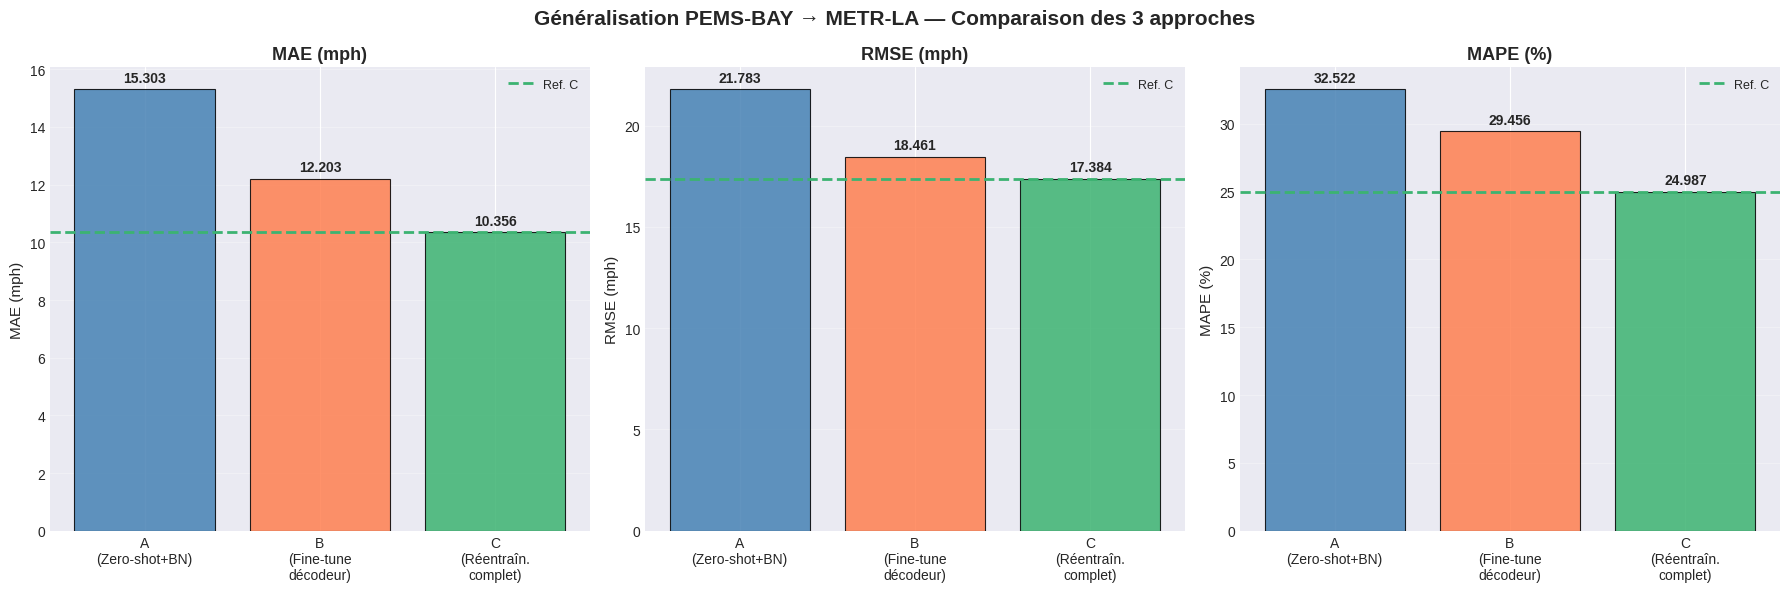


✅ Visualisation sauvegardée.
🏁 PROGRAMME TERMINÉ


In [31]:
# =============================================================================
# SECTION 12: VISUALISATION COMPARATIVE
# =============================================================================
print("="*80)
print("🔴 SECTION 12: VISUALISATION")
print("="*80)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Généralisation PEMS-BAY → METR-LA — Comparaison des 3 approches',
             fontsize=15, fontweight='bold')

approach_labels = ['A\n(Zero-shot+BN)', 'B\n(Fine-tune\ndécodeur)', 'C\n(Réentraîn.\ncomplet)']
colors = ['steelblue', 'coral', 'mediumseagreen']
approach_keys = ['A', 'B', 'C']

for ax, metric, title in zip(axes, ['MAE', 'RMSE', 'MAPE'], ['MAE (mph)', 'RMSE (mph)', 'MAPE (%)']):
    vals = [all_results[k][metric] for k in approach_keys]
    bars = ax.bar(approach_labels, vals, color=colors, alpha=0.85, edgecolor='black', linewidth=0.8)
    # Ligne de référence = Approche C
    ax.axhline(all_results['C'][metric], color='mediumseagreen', linestyle='--', linewidth=2, label='Ref. C')
    # Valeurs au-dessus des barres
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel(title, fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(config.RESULTS_SAVE_PATH, 'generalization_comparison.png'),
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("\n✅ Visualisation sauvegardée.")
print("="*80)
print("🏁 PROGRAMME TERMINÉ")
print("="*80)
